# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** Sadaruwan I J M J<br>
**Index number:** 220542J<br>
**GitHub repository:** https://github.com/JeewanthaSadaruwan/EN4554-Assignment2-CNNs

## 1. Setup

Imports, device selection and fixed random seeds so that results are reproducible.

In [1]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.datasets import CIFAR10

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True   # faster convolutions for fixed input sizes

print("PyTorch    :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Device     :", device, f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")

PyTorch    : 2.11.0+cu128
torchvision: 0.26.0+cu128
Device     : cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


## 1.1 Data: CIFAR-10

CIFAR-10 has 60,000 colour images of size 32×32 in 10 classes (50,000 training and 10,000 test images). It is loaded with `torchvision.datasets.CIFAR10` and stored in `./data`.

This single data pipeline is used by every task:
- The 50k training images are split into **45k train / 5k validation** with a fixed seed.
- Images are **normalized per channel using statistics of the 45k training split only**.
- The **test set is used only once**, in Task 4.

In [2]:

import random
import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Load original CIFAR-10 training dataset
dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

# Split: 45,000 train / 5,000 validation
generator = torch.Generator().manual_seed(seed)
indices = torch.randperm(len(dataset), generator=generator)

train_indices = indices[:45000].tolist()
val_indices = indices[45000:].tolist()

# Calculate statistics from training subset only
stats_loader = DataLoader(
    Subset(dataset, train_indices),
    batch_size=512,
    shuffle=False,
    num_workers=0
)

channel_sum = torch.zeros(3, dtype=torch.float64)
channel_sq_sum = torch.zeros(3, dtype=torch.float64)
num_pixels = 0

for images, _ in stats_loader:
    images = images.double()

    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sq_sum += (images ** 2).sum(dim=(0, 2, 3))

    num_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / num_pixels
std = (channel_sq_sum / num_pixels - mean ** 2).clamp_min(0).sqrt()

print("Training mean:", mean)
print("Training std:", std)

# Apply training statistics to both subsets
dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist())
])

train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(seed)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))


Training mean: tensor([0.4917, 0.4823, 0.4467], dtype=torch.float64)
Training std: tensor([0.2471, 0.2435, 0.2616], dtype=torch.float64)
Training samples: 45000
Validation samples: 5000


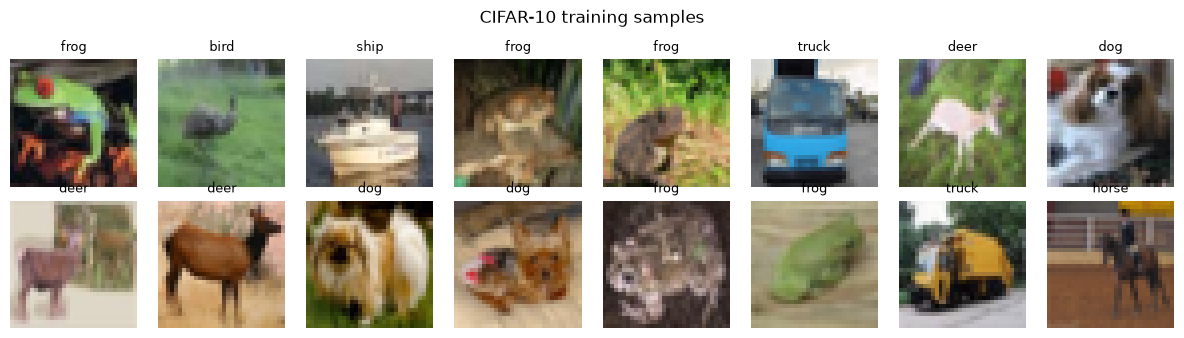

In [3]:
# A few training images with their labels (raw pixels, before normalization)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, idx in zip(axes.flat, train_indices[:16]):
    ax.imshow(dataset.data[idx])
    ax.set_title(dataset.classes[dataset.targets[idx]], fontsize=9)
    ax.axis("off")
plt.suptitle("CIFAR-10 training samples")
plt.tight_layout()
plt.show()

## Task 1: Backpropagation

**(a)** Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward (no autograd), and assemble an MLP.

#### 1. Linear Layer Implementation (Forward and Backward Pass)

In [4]:
import torch

torch.manual_seed(42)

class Linear:
    def __init__(self, in_features, out_features):

        self.W = torch.randn(
            in_features, out_features
        ) * (2.0 / in_features) ** 0.5

        self.b = torch.zeros(1, out_features)

    def forward(self, X):
        self.X = X
        Y = X @ self.W + self.b
        return Y

    def backward(self, dY):
        dX = dY @ self.W.T
        self.dW = self.X.T @ dY
        self.db = torch.sum(
            dY, dim=0, keepdim=True
        )
        return dX


#### 2. ReLU Activation Function Implementation (Forward and Backward Pass)

In [5]:

class ReLU:
    def forward(self, X):
        self.X = X
        Y = torch.clamp(X, min=0)
        return Y

    def backward(self, dY):
        dX = dY * (self.X > 0)
        return dX


#### 3. Softmax Cross-Entropy Loss Implementation (Forward and Backward Pass)

In [6]:
class SoftmaxCrossEntropy:

    def forward(self, logits, labels):
        N = logits.shape[0]

        shifted = logits - logits.max(dim=1, keepdim=True).values
        exp_scores = torch.exp(shifted)

        self.probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)
        self.labels = labels

        log_probs = shifted - torch.log(exp_scores.sum(dim=1, keepdim=True))

        loss = -log_probs[torch.arange(N, device=logits.device), labels].mean()

        return loss

    def backward(self):
        N = self.labels.shape[0]
        dZ = self.probs.clone()
        dZ[torch.arange(N, device=dZ.device), self.labels] -= 1
        dZ = dZ / N

        return dZ


#### 4. Multi-Layer Perceptron (MLP) Assembly and Backpropagation

**MLP Network Architecture** (example: 3 input features, 2 hidden layers with 5 neurons each, 3 output neurons)

- **Input layer:** 3 features, so the input has shape $(N, 3)$.
- **Hidden layer 1:** `Linear(3, 5)` followed by `ReLU`. $W_1$ is $3 \times 5$ and $b_1$ is $1 \times 5$.
- **Hidden layer 2:** `Linear(5, 5)` followed by `ReLU`. $W_2$ is $5 \times 5$ and $b_2$ is $1 \times 5$.
- **Output layer:** `Linear(5, 3)` produces 3 logits (one per class). $W_3$ is $5 \times 3$ and $b_3$ is $1 \times 3$.
- **Loss:** softmax cross-entropy is applied to the logits.
- **Forward pass:** $X \rightarrow$ Linear $\rightarrow$ ReLU $\rightarrow$ Linear $\rightarrow$ ReLU $\rightarrow$ Linear $\rightarrow$ logits $\rightarrow$ loss.
- **Backward pass:** the loss gradient $\partial L / \partial \text{logits}$ is passed through the layers in reverse order. Each layer computes the gradients of its own parameters and returns $\partial L / \partial X$ to the layer before it.
- **Total parameters:** $(3 \cdot 5 + 5) + (5 \cdot 5 + 5) + (5 \cdot 3 + 3) = 20 + 30 + 18 = 68$.

In [7]:

class MLP:
    def __init__(self, input_size, hidden1, hidden2, output_size):
        self.layers = [
            Linear(input_size, hidden1),
            ReLU(),
            Linear(hidden1, hidden2),
            ReLU(),
            Linear(hidden2, output_size)
        ]

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, dY):
        for layer in reversed(self.layers):
            dY = layer.backward(dY)
        return dY


**(b)** Verify your gradients against autograd and against centred finite differences; report the relative errors. Use `torch.allclose` to check whether the gradients match.


### 1. Manual Gradient Computation and Collection

A small MLP with architecture **3–5–5–3** is initialized using two input samples. Double-precision (`float64`) tensors are used to improve numerical accuracy during gradient verification.

The forward pass computes the softmax cross-entropy loss, while the manually implemented backward pass calculates the gradients using the chain rule.

Finally, the model's weights and biases are stored in `params`, and their corresponding gradients, along with the input gradient, are stored in `manual_grads` for comparison with PyTorch autograd and centred finite differences.


In [8]:

import torch
import torch.nn.functional as F

torch.manual_seed(42)

# Small MLP for gradient checking
model = MLP(3, 5, 5, 3)

# Convert parameters to float64 for accurate numerical checks
for layer in model.layers:
    if isinstance(layer, Linear):
        layer.W = layer.W.double()
        layer.b = layer.b.double()

# Two samples, three input features
X = torch.randn(2, 3, dtype=torch.float64)
labels = torch.tensor([0, 2], dtype=torch.long)

criterion = SoftmaxCrossEntropy()

# Forward pass
logits = model.forward(X)
loss = criterion.forward(logits, labels)

# Manual backward pass
dZ = criterion.backward()
dX = model.backward(dZ)

# Collect parameters and manual gradients
params = {}
manual_grads = {"X": dX.detach().clone()}

for i, layer in enumerate(model.layers):
    if isinstance(layer, Linear):
        params[f"layer{i}.W"] = layer.W
        params[f"layer{i}.b"] = layer.b

        manual_grads[f"layer{i}.W"] = layer.dW.detach().clone()
        manual_grads[f"layer{i}.b"] = layer.db.detach().clone()
print("Manual loss:", loss.item())


Manual loss: 2.451002982173198


In [9]:
torch.set_printoptions(precision=4, sci_mode=False)

for i, layer in enumerate(model.layers):
    if isinstance(layer, Linear):
        print(f"\n{'='*45}")
        print(f"LINEAR LAYER {i}")
        print(f"{'='*45}")

        print("\nWeight Matrix (W):")
        print(layer.W)

        print("\nWeight Gradient (dL/dW):")
        print(layer.dW)

        print("\nBias Vector (b):")
        print(layer.b)

        print("\nBias Gradient (dL/db):")
        print(layer.db)

print("\nInput Gradient (dL/dX):")
print(dX)


LINEAR LAYER 0

Weight Matrix (W):
tensor([[ 0.2749,  0.1052,  0.1914,  0.1881, -0.9168],
        [-0.1521,  1.8030, -0.5209,  0.3769,  0.2183],
        [ 0.4367,  0.6608,  0.9065, -1.3797, -0.8075]], dtype=torch.float64)

Weight Gradient (dL/dW):
tensor([[ 1.0034,  0.0000,  1.2151,  0.0966,  0.0000],
        [-0.8962,  0.0000, -1.0989, -0.0005,  0.0000],
        [ 0.2668,  0.0000,  0.3339, -0.0425,  0.0000]], dtype=torch.float64)

Bias Vector (b):
tensor([[0., 0., 0., 0., 0.]], dtype=torch.float64)

Bias Gradient (dL/db):
tensor([[0.5858, 0.0000, 0.6843, 0.2144, 0.0000]], dtype=torch.float64)

LINEAR LAYER 2

Weight Matrix (W):
tensor([[-0.8757, -0.5510, -0.1413,  1.0862,  0.2017],
        [-0.2685,  0.1934, -0.4899, -0.9851, -0.5834],
        [ 1.1456,  0.1016,  0.2323,  0.1109,  0.8761],
        [-0.2820,  0.9140,  0.4477, -0.6804,  0.3388],
        [ 0.7434,  0.3549, -0.2863, -0.4881, -0.1089]], dtype=torch.float64)

Weight Gradient (dL/dW):
tensor([[ 0.4084,  0.0022,  0.3711,  0.


### 2. Automatic Gradient Computation Using PyTorch Autograd

The same MLP architecture **3–5–5–3**, input samples, weights, and biases from the manual implementation are used to ensure a fair gradient comparison. Independent copies of the input and parameters are created with `requires_grad=True` to enable PyTorch's automatic differentiation.

The forward pass is performed using PyTorch tensor operations, and the cross-entropy loss is calculated using the built-in `F.cross_entropy()` function. The `auto_loss.backward()` operation automatically computes the gradients using the chain rule.

Finally, the automatically calculated gradients of all weights, biases, and inputs are stored in `autograd_grads` for comparison with the manually computed gradients and verification of the backpropagation implementation.


In [10]:

# Create independent tensors for autograd
X_auto = X.detach().clone().requires_grad_(True)

auto_params = {
    name: p.detach().clone().requires_grad_(True)
    for name, p in params.items()
}
# Forward pass using PyTorch operations
A = X_auto
for i, layer in enumerate(model.layers):
    if isinstance(layer, Linear):
        A = (
            A @ auto_params[f"layer{i}.W"]
            + auto_params[f"layer{i}.b"]
        )
    elif isinstance(layer, ReLU):
        A = torch.relu(A)

# PyTorch's built-in cross-entropy
auto_loss = F.cross_entropy(A, labels)

# Automatic backpropagation
auto_loss.backward()

# Collect autograd gradients
autograd_grads = {
    "X": X_auto.grad.detach().clone()
}

for name, tensor in auto_params.items():
    autograd_grads[name] = tensor.grad.detach().clone()



### 3. Gradient Verification: Manual Backpropagation vs. PyTorch Autograd

The manually calculated gradients are compared with those obtained using PyTorch autograd to verify the correctness of the implemented backward passes.

The `relative_error()` function computes the normalized L2 difference between the two gradient tensors. A relative error close to zero indicates strong agreement between the gradients.

Additionally, `torch.allclose()` checks whether the corresponding gradient values match within the specified tolerances (`rtol=1e-4`, `atol=1e-6`). The comparison is performed for all weight matrices, bias vectors, and input gradients, reporting both the relative errors and matching results.


In [11]:

def relative_error(a, b):
    numerator = torch.linalg.vector_norm(a - b)
    denominator = (
        torch.linalg.vector_norm(a)
        + torch.linalg.vector_norm(b)
        + 1e-12
    )
    return (numerator / denominator).item()


print("Manual vs Autograd")

for name in manual_grads:
    g_manual = manual_grads[name]
    g_auto = autograd_grads[name]

    error = relative_error(g_manual, g_auto)
    match = torch.allclose(
        g_manual, g_auto,
        rtol=1e-4, atol=1e-6
    )

    print(f"{name:12s} Error: {error:.3e}  Match: {match}")


Manual vs Autograd
X            Error: 0.000e+00  Match: True
layer0.W     Error: 0.000e+00  Match: True
layer0.b     Error: 0.000e+00  Match: True
layer2.W     Error: 1.280e-17  Match: True
layer2.b     Error: 2.366e-17  Match: True
layer4.W     Error: 5.613e-18  Match: True
layer4.b     Error: 3.581e-17  Match: True



### 4. Numerical Gradient Computation Using Centred Finite Differences

The gradients of the MLP are independently approximated using the centred finite-difference method, without applying backpropagation or automatic differentiation.

Each input, weight, and bias element is perturbed by a small value (`h=1e-5`). The loss is evaluated at both the positively and negatively perturbed values, and the numerical gradient is estimated using:

$$
\frac{\partial L}{\partial w}
\approx
\frac{L(w+h)-L(w-h)}{2h}
$$

The original parameter values are restored after each calculation. Finally, the estimated gradients are stored in `numerical_grads` for comparison with the manually calculated gradients and PyTorch autograd.


In [12]:

def numerical_gradient(tensor, h=1e-5):

    grad = torch.zeros_like(tensor)

    flat_tensor = tensor.reshape(-1)
    flat_grad = grad.reshape(-1)

    for j in range(flat_tensor.numel()):

        original = flat_tensor[j].item()

        # Calculate L(w + h)
        with torch.no_grad():
            flat_tensor[j] = original + h

        loss_plus = criterion.forward(
            model.forward(X), labels
        ).item()

        # Calculate L(w - h)
        with torch.no_grad():
            flat_tensor[j] = original - h

        loss_minus = criterion.forward(
            model.forward(X), labels
        ).item()

        # Restore original parameter
        with torch.no_grad():
            flat_tensor[j] = original

        # Centred finite difference
        flat_grad[j] = (
            loss_plus - loss_minus
        ) / (2 * h)

    return grad


# Calculate numerical gradients
numerical_grads = {}

for name, tensor in {"X": X, **params}.items():
    numerical_grads[name] = numerical_gradient(tensor)


In [13]:

print(
    f"{'Parameter':<12} "
    f"{'Autograd Error':>15} "
    f"{'FD Error':>15} "
    f"{'Autograd Match':>16} "
    f"{'FD Match':>10}"
)

print("-" * 76)

for name in manual_grads:

    manual = manual_grads[name]
    auto = autograd_grads[name]
    numeric = numerical_grads[name]

    error_auto = relative_error(manual, auto)
    error_fd = relative_error(manual, numeric)

    match_auto = torch.allclose(
        manual, auto, rtol=1e-4, atol=1e-6
    )

    match_fd = torch.allclose(
        manual, numeric, rtol=1e-4, atol=1e-6
    )

    print(
        f"{name:<12} "
        f"{error_auto:>15.3e} "
        f"{error_fd:>15.3e} "
        f"{str(match_auto):>16} "
        f"{str(match_fd):>10}"
    )


Parameter     Autograd Error        FD Error   Autograd Match   FD Match
----------------------------------------------------------------------------
X                  0.000e+00       2.091e-11             True       True
layer0.W           0.000e+00       1.592e-11             True       True
layer0.b           0.000e+00       1.190e-11             True       True
layer2.W           1.280e-17       1.296e-11             True       True
layer2.b           2.366e-17       9.839e-12             True       True
layer4.W           5.613e-18       1.584e-11             True       True
layer4.b           3.581e-17       6.493e-12             True       True



### 6. Gradient Verification Results and Discussion

The manually computed gradients were compared against PyTorch autograd and centred finite differences for all input, weight, and bias tensors.

The relative errors between manual backpropagation and autograd were extremely small (approximately $0$ to $10^{-17}$), indicating near-exact agreement. The finite-difference relative errors were also very small, ranging from approximately $10^{-12}$ to $10^{-11}$, with minor differences arising from numerical approximation and floating-point precision.

All comparisons returned `True` using `torch.allclose()` with `rtol=1e-4` and `atol=1e-6`.

**Conclusion:** The results confirm that the manually implemented backward passes for the Linear, ReLU, and Softmax Cross-Entropy layers are numerically consistent with both automatic differentiation and finite-difference approximations, supporting the correctness of the MLP's backpropagation implementation for the tested inputs.


**(c)** Train it with SGD on flattened CIFAR-10 images; plot the loss and report validation accuracy.

### 1. Data

The MLP uses the 45k/5k split, the training-set normalization, and the `train_loader` / `val_loader` (batch size 128) created in Section 1.1. Each 3×32×32 image is flattened into a 3072-dimensional vector.


### 2. MLP Initialization and Manual SGD Implementation

An MLP with architecture **3072–128–64–10** is initialized for CIFAR-10 classification. Each image is flattened into a 3072-dimensional input vector, and the output layer produces 10 logits.

A manual SGD update function is implemented to update the weights and biases of each Linear layer using gradients obtained from the custom backward passes.



The model parameters are updated using the standard SGD update rule:

$$
W_{t+1}=W_t-\eta\frac{\partial L}{\partial W_t}
$$

$$
b_{t+1}=b_t-\eta\frac{\partial L}{\partial b_t}
$$

where $\eta$ is the learning rate, and the gradients are calculated using the manually implemented backward passes.


In [38]:

# Select CPU or GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create a new model with float32 parameters
model = MLP(3072, 128, 64, 10)

# Move custom layer parameters to device
for layer in model.layers:
    if isinstance(layer, Linear):
        layer.W = layer.W.to(device)
        layer.b = layer.b.to(device)

criterion = SoftmaxCrossEntropy()

learning_rate = 0.05
epochs = 30

# Manual SGD optimizer
def sgd_step(model, lr):
    with torch.no_grad():
        for layer in model.layers:
            if isinstance(layer, Linear):
                layer.W -= lr * layer.dW
                layer.b -= lr * layer.db

print("Device:", device)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)


Device: cuda
Learning rate: 0.05
Epochs: 30



### 3. MLP Training Using Mini-Batch Stochastic Gradient Descent

The MLP is trained on flattened CIFAR-10 images using mini-batch SGD. For each batch, the forward pass calculates the average cross-entropy loss, and the manually implemented backward pass computes the gradients.

The model parameters are updated using the SGD rule after each batch. Training loss is averaged across all training samples for each epoch, while validation accuracy is evaluated separately without performing weight updates.


With 45,000 training samples and a mini-batch size of 128, each epoch consists of 352 mini-batches. Therefore, 352 forward passes, backward passes, and SGD parameter updates are performed per epoch.


In [39]:

from tqdm.auto import tqdm

train_losses = []
val_accuracies = []

for epoch in range(epochs):

    # -------- TRAINING --------
    total_loss = 0.0
    total_samples = 0

    print(f"\nEpoch {epoch + 1}/{epochs}")

    progress_bar = tqdm(
        train_loader,
        desc=f"Training Epoch {epoch + 1}",
        leave=True
    )

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        # Flatten images
        X = images.reshape(images.shape[0], -1)

        # Forward pass
        logits = model.forward(X)
        loss = criterion.forward(logits, labels)

        # Manual backward pass
        dZ = criterion.backward()
        model.backward(dZ)

        # SGD update
        sgd_step(model, learning_rate)

        # Accumulate training loss
        total_loss += loss.item() * X.shape[0]
        total_samples += X.shape[0]

        # Display live training loss
        running_loss = total_loss / total_samples

        progress_bar.set_postfix(
            loss=f"{running_loss:.4f}"
        )

    epoch_loss = total_loss / total_samples
    train_losses.append(epoch_loss)

    # -------- VALIDATION --------
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            X = images.reshape(images.shape[0], -1)

            logits = model.forward(X)
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.shape[0]

    val_accuracy = 100.0 * correct / total
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} Completed | "
        f"Train Loss: {epoch_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )



Epoch 1/30


Training Epoch 1:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 01/30 Completed | Train Loss: 1.7578 | Val Accuracy: 43.16%

Epoch 2/30


Training Epoch 2:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 02/30 Completed | Train Loss: 1.5178 | Val Accuracy: 44.92%

Epoch 3/30


...

Epoch 28/30 Completed | Train Loss: 0.7050 | Val Accuracy: 49.02%

Epoch 29/30


Training Epoch 29:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 29/30 Completed | Train Loss: 0.6928 | Val Accuracy: 47.90%

Epoch 30/30


Training Epoch 30:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch 30/30 Completed | Train Loss: 0.6722 | Val Accuracy: 47.96%



### 4. Training Loss and Validation Accuracy Analysis

The training loss is plotted against epochs to examine the convergence behavior of the manually implemented MLP.

Validation accuracy is also plotted to evaluate the model's classification performance on unseen validation samples. These results are used to assess the effectiveness of mini-batch SGD training.


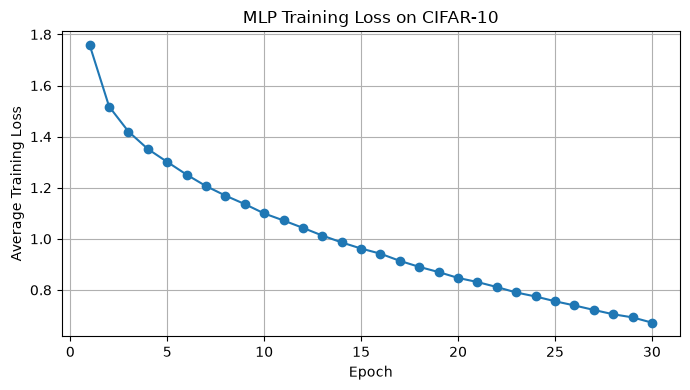

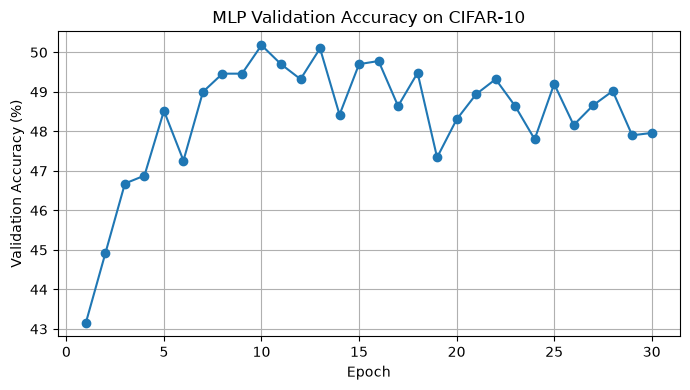

Final Training Loss: 0.6722
Final Validation Accuracy: 47.96%
Best Validation Accuracy: 50.18%


In [41]:

import matplotlib.pyplot as plt

epoch_numbers = range(1, len(train_losses) + 1)

# Figure 1: Training loss
plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("MLP Training Loss on CIFAR-10")
plt.grid(True)
plt.tight_layout()
plt.show()

# Figure 2: Validation accuracy
plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, val_accuracies, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("MLP Validation Accuracy on CIFAR-10")
plt.grid(True)
plt.tight_layout()
plt.show()

# Final results
print(f"Final Training Loss: {train_losses[-1]:.4f}")
print(f"Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"Best Validation Accuracy: {max(val_accuracies):.2f}%")



**Figure 1: Training Loss vs. Epoch**

The training loss curve illustrates how the average cross-entropy loss changes during mini-batch SGD training. A decreasing training loss indicates that the optimizer is successfully minimizing the training objective.

**Figure 2: Validation Accuracy vs. Epoch**

The validation accuracy curve illustrates the model's classification performance on the 5,000 held-out validation images. It is used to evaluate generalization and identify whether additional training improves performance on unseen samples.



### 5. Experimental Results and Discussion

The manually implemented Multi-Layer Perceptron (MLP), with architecture **3072–128–64–10**, was trained on 45,000 flattened CIFAR-10 training images using mini-batch Stochastic Gradient Descent (SGD) for **30 epochs**. A batch size of 128 and a fixed learning rate of 0.05 were used.

#### Training Loss Analysis

The training loss curve (Figure 1) illustrates the optimization behavior of the MLP over 30 epochs.

The final average training loss was **0.6722**. The curve can be used to determine whether the manually implemented backpropagation and SGD updates successfully minimize the training objective.

#### Validation Accuracy Analysis

The validation accuracy curve (Figure 2) shows a rapid improvement during the initial training epochs, increasing from approximately 43% to 50%.

The highest validation accuracy was achieved around epoch 10. However, further training did not produce sustained improvements, and validation accuracy fluctuated during the remaining epochs.

The best and final validation accuracies were:

- **Best validation accuracy:** 50.18%
- **Best epoch:** 10
- **Final validation accuracy:** 47.96%

The observed validation fluctuations suggest that increasing the number of training epochs alone does not necessarily improve generalization. Possible contributing factors include optimization variability, the fixed learning rate, and overfitting.

#### Discussion

The MLP is able to learn useful classification patterns from flattened CIFAR-10 images. However, flattening removes the explicit spatial arrangement of image pixels, making it difficult for a fully connected network to exploit local image features compared with convolutional neural networks.

The experiment also demonstrates that improvements in the training objective do not always result in corresponding improvements in validation accuracy.

### 6. Conclusion

The manually implemented MLP was successfully trained using mini-batch SGD without relying on PyTorch autograd for gradient computation.

The experiment demonstrates that the custom forward propagation, backward propagation, and SGD parameter updates can be used to train a neural network for image classification.

Validation performance improved during the initial epochs but showed limited further improvement during extended training. Potential improvements include learning-rate scheduling, regularization, and early stopping.


**(d)** For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU. Explain.


### 1. Sigmoid Activation Function Implementation

The sigmoid activation function is implemented with explicit forward and backward passes. Its derivative is calculated manually without using PyTorch autograd.

The sigmoid derivative is bounded above by 0.25, which can cause gradients to become very small when propagated through many layers.


In [42]:

class Sigmoid:
    def forward(self, X):
        self.Y = torch.sigmoid(X)
        return self.Y

    def backward(self, dY):
        dX = dY * self.Y * (1 - self.Y)
        return dX



### 2. Construction of a 10-Layer MLP

A deep MLP containing 10 Linear layers is constructed with nine hidden layers of 128 neurons and an output layer of 10 neurons.

The network supports either Sigmoid or ReLU activation functions between consecutive Linear layers. The same manually implemented Linear and Softmax Cross-Entropy classes are reused.


In [43]:

class DeepMLP:
    def __init__(self, activation="relu"):

        # 3072 -> nine hidden layers (128) -> 10
        sizes = [3072] + [128] * 9 + [10]

        self.layers = []

        for i in range(len(sizes) - 1):

            # Add Linear layer
            self.layers.append(
                Linear(sizes[i], sizes[i + 1])
            )

            # Activation after every Linear layer
            # except the final output layer
            if i < len(sizes) - 2:
                if activation == "sigmoid":
                    self.layers.append(Sigmoid())
                elif activation == "relu":
                    self.layers.append(ReLU())
                else:
                    raise ValueError("Unknown activation")

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, dY):
        for layer in reversed(self.layers):
            dY = layer.backward(dY)
        return dY



### 3. Per-Layer Gradient Norm Computation at Initialization

Two 10-layer MLPs are initialized with identical weights and biases, using Sigmoid and ReLU activations respectively. The existing He initialization from the custom Linear class is used for both networks to isolate the effect of the activation function.

A single mini-batch of normalized, flattened CIFAR-10 images is passed through each network. Manual backpropagation computes the weight gradients, and their Frobenius norms are recorded for all 10 Linear layers.

No parameter updates are performed, ensuring that the gradients are measured at initialization.


In [44]:

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Get one batch from the training dataset
images, labels = next(iter(train_loader))

X_batch = images.to(device).reshape(images.shape[0], -1)
y_batch = labels.to(device)

# Initialize both networks with identical parameters
torch.manual_seed(123)
model_sigmoid = DeepMLP(activation="sigmoid")

torch.manual_seed(123)
model_relu = DeepMLP(activation="relu")

# Move parameters to device
for net in [model_sigmoid, model_relu]:
    for layer in net.layers:
        if isinstance(layer, Linear):
            layer.W = layer.W.to(device)
            layer.b = layer.b.to(device)

# Verify identical initial weights
sig_linear = [l for l in model_sigmoid.layers
              if isinstance(l, Linear)]
relu_linear = [l for l in model_relu.layers
              if isinstance(l, Linear)]

assert all(
    torch.equal(a.W, b.W) and torch.equal(a.b, b.b)
    for a, b in zip(sig_linear, relu_linear)
)

def get_gradient_norms(net, X, labels):
    criterion = SoftmaxCrossEntropy()

    with torch.no_grad():

        # Forward pass
        logits = net.forward(X)
        loss = criterion.forward(logits, labels)

        # Manual backward pass
        dZ = criterion.backward()
        net.backward(dZ)

        # Frobenius norm of dW for each Linear layer
        norms = [
            torch.linalg.vector_norm(layer.dW).item()
            for layer in net.layers
            if isinstance(layer, Linear)
        ]

    return norms, loss.item()


sigmoid_norms, sigmoid_loss = get_gradient_norms(
    model_sigmoid, X_batch, y_batch
)

relu_norms, relu_loss = get_gradient_norms(
    model_relu, X_batch, y_batch
)

print("Sigmoid initial loss:", sigmoid_loss)
print("ReLU initial loss:", relu_loss)

print(f"\n{'Layer':<10} {'Sigmoid norm':>16} {'ReLU norm':>16}")
print("-" * 44)

for i, (s, r) in enumerate(zip(sigmoid_norms, relu_norms), 1):
    print(f"{i:<10} {s:>16.6e} {r:>16.6e}")


Sigmoid initial loss: 2.58624529838562
ReLU initial loss: 3.515939474105835

Layer          Sigmoid norm        ReLU norm
--------------------------------------------
1              1.897985e-04     9.039480e+00
2              1.685751e-04     2.801434e+00
3              5.733613e-04     3.594818e+00
4              1.858048e-03     4.192280e+00
5              6.393338e-03     4.652304e+00
6              1.901324e-02     4.813894e+00
7              5.713546e-02     4.403132e+00
8              1.800686e-01     4.346558e+00
9              5.832621e-01     4.891616e+00
10             1.828008e+00     6.025620e+00



### 4. Comparison of Per-Layer Gradient Norms: Sigmoid vs. ReLU

The Frobenius norms of the weight gradients are plotted against the Linear layer index for both activation functions.

A logarithmic vertical axis is used because gradient magnitudes can differ by several orders of magnitude. This visualization helps identify whether gradients diminish as they propagate toward the earlier layers.


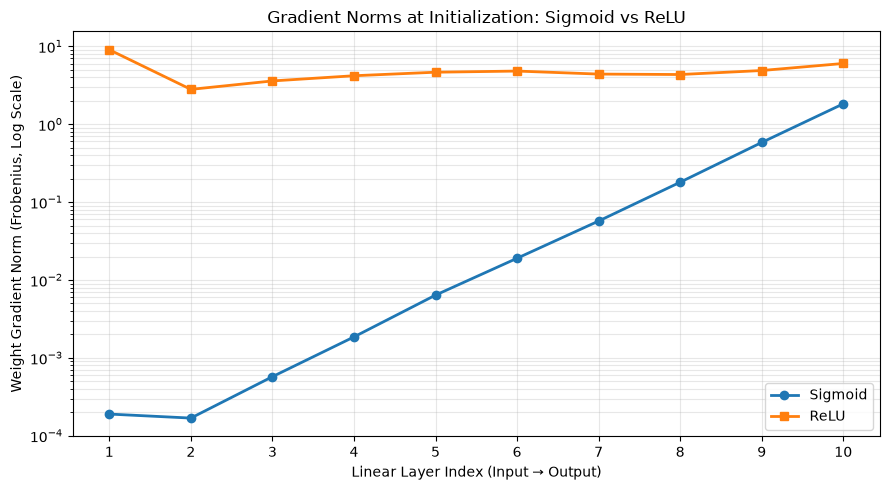

In [45]:

import matplotlib.pyplot as plt

layer_numbers = range(1, 11)

plt.figure(figsize=(9, 5))

plt.plot(
    layer_numbers,
    sigmoid_norms,
    marker="o",
    linewidth=2,
    label="Sigmoid"
)

plt.plot(
    layer_numbers,
    relu_norms,
    marker="s",
    linewidth=2,
    label="ReLU"
)

plt.yscale("log")

plt.xlabel("Linear Layer Index (Input → Output)")
plt.ylabel("Weight Gradient Norm (Frobenius, Log Scale)")
plt.title("Gradient Norms at Initialization: Sigmoid vs ReLU")

plt.xticks(list(layer_numbers))
plt.grid(True, which="both", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()



### 5. Experimental Results and Discussion

The gradient propagation behavior of a 10-layer MLP was investigated using Sigmoid and ReLU activation functions. Both networks were initialized with identical weights and biases, and gradients were calculated using manual backpropagation on the same CIFAR-10 mini-batch, without performing any parameter updates.

The Frobenius norm of the weight gradient was calculated for each Linear layer:

$$
G_l = \left\|\frac{\partial L}{\partial W_l}\right\|_F
$$

The resulting gradient norms were plotted against the layer index using a logarithmic scale.

#### Sigmoid Activation

The Sigmoid network exhibits a clear vanishing gradient problem. The gradient norm decreases from approximately **1.828 at Layer 10** to **0.000190 at Layer 1**, representing a reduction of approximately 9,600 times.

This occurs because the Sigmoid derivative is bounded by 0.25:

$$
\sigma'(z)=\sigma(z)(1-\sigma(z))\leq 0.25
$$

During backpropagation, repeated multiplication by small derivatives can significantly reduce the gradients reaching earlier layers. Consequently, these layers may learn very slowly during training.

#### ReLU Activation

In contrast, the ReLU network maintains substantially larger gradient norms, ranging approximately from **2.8 to 9.0** across the ten layers.

The ReLU derivative is:

$$
\operatorname{ReLU}'(z)=
\begin{cases}
1, & z>0\\
0, & z\leq0
\end{cases}
$$

Unlike Sigmoid, ReLU does not reduce gradients through its active neurons. This allows gradients to propagate more effectively through deep networks, although inactive neurons can still receive zero gradients.

#### Effect of Initialization

Both networks use the same He initialization and identical initial parameters to provide a controlled comparison of activation functions.

He initialization is primarily designed for ReLU-based networks. Therefore, the observed gradient behavior also depends on the initialization method, and the results should not be interpreted as universally applicable to every initialization strategy.

### 6. Conclusion

The experiment demonstrates the significant influence of activation functions on gradient propagation in deep neural networks.

The Sigmoid network exhibits severe vanishing gradients in its earlier layers, whereas the ReLU network maintains relatively stable and substantially larger gradient norms.

These findings illustrate why ReLU is generally preferred over Sigmoid in deep feedforward neural networks, particularly when avoiding vanishing gradients is important.


## Task 2: Optimizers

**(a)** Implement SGD with momentum and Adam (with bias correction) as `torch.optim.Optimizer` subclasses. Show that they match `torch.optim.SGD` and `torch.optim.Adam`.


### 1. SGD with Momentum Implementation

SGD with momentum extends standard stochastic gradient descent by maintaining a momentum buffer that combines the current gradient with information from previous optimization steps.

The update equations are:

$$
v_t = \mu v_{t-1} + g_t
$$

$$
\theta_{t+1} = \theta_t - \eta v_t
$$

where $\eta$ is the learning rate, $\mu$ is the momentum coefficient, and $g_t$ is the current gradient.

A custom optimizer is implemented by subclassing `torch.optim.Optimizer`. The momentum buffer is stored separately for each parameter. Following PyTorch's convention, the first momentum buffer is initialized with the first gradient.


In [46]:

import torch
from torch.optim import Optimizer

class SGDMomentumCustom(Optimizer):

    def __init__(self, params, lr=0.01, momentum=0.9):

        if lr < 0:
            raise ValueError("Learning rate must be non-negative")

        if momentum < 0:
            raise ValueError("Momentum must be non-negative")

        defaults = dict(lr=lr, momentum=momentum)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):

        loss = None

        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:

            lr = group["lr"]
            mu = group["momentum"]

            for p in group["params"]:

                if p.grad is None:
                    continue

                grad = p.grad

                if grad.is_sparse:
                    raise RuntimeError(
                        "Sparse gradients are not supported"
                    )

                if mu != 0:

                    state = self.state[p]

                    # First step: initialize momentum buffer
                    if "momentum_buffer" not in state:
                        state["momentum_buffer"] = (
                            grad.detach().clone()
                        )

                    # Subsequent steps: update momentum buffer
                    else:
                        state["momentum_buffer"].mul_(mu).add_(grad)

                    grad = state["momentum_buffer"]

                # Update parameter: p = p - lr * grad
                p.add_(grad, alpha=-lr)

        return loss



### 2. Adam Optimizer Implementation with Bias Correction

Adam (Adaptive Moment Estimation) is implemented by maintaining exponential moving averages of the gradients (first moment) and squared gradients (second moment).

The moment estimates are updated using:

$$
m_t = \beta_1m_{t-1}+(1-\beta_1)g_t
$$

$$
v_t = \beta_2v_{t-1}+(1-\beta_2)g_t^2
$$

Bias correction compensates for the zero initialization of the moment estimates:

$$
\hat m_t=\frac{m_t}{1-\beta_1^t},
\qquad
\hat v_t=\frac{v_t}{1-\beta_2^t}
$$

The parameters are updated using:

$$
\theta_{t+1}=\theta_t-\eta
\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}
$$

A custom Adam optimizer is implemented as a `torch.optim.Optimizer` subclass, with separate first-moment, second-moment, and step-count states maintained for each parameter.


In [47]:

import math

class AdamCustom(Optimizer):

    def __init__(
        self,
        params,
        lr=0.001,
        betas=(0.9, 0.999),
        eps=1e-8
    ):

        if lr < 0:
            raise ValueError("Learning rate must be non-negative")

        if not (0 <= betas[0] < 1 and 0 <= betas[1] < 1):
            raise ValueError("Beta values must be in [0, 1)")

        if eps < 0:
            raise ValueError("Epsilon must be non-negative")

        defaults = dict(lr=lr, betas=betas, eps=eps)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):

        loss = None

        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:

            lr = group["lr"]
            beta1, beta2 = group["betas"]
            eps = group["eps"]

            for p in group["params"]:

                if p.grad is None:
                    continue

                grad = p.grad

                if grad.is_sparse:
                    raise RuntimeError(
                        "Sparse gradients are not supported"
                    )

                state = self.state[p]

                # Initialize optimizer state
                if len(state) == 0:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(p)
                    state["exp_avg_sq"] = torch.zeros_like(p)

                # Increase step count
                state["step"] += 1
                t = state["step"]

                m = state["exp_avg"]
                v = state["exp_avg_sq"]

                # Update first moment
                m.mul_(beta1).add_(
                    grad, alpha=1 - beta1
                )

                # Update second moment
                v.mul_(beta2).addcmul_(
                    grad, grad, value=1 - beta2
                )

                # Bias correction
                bias_correction1 = 1 - beta1 ** t
                bias_correction2 = 1 - beta2 ** t

                # Adam parameter update
                step_size = lr / bias_correction1

                denominator = (
                    v.sqrt() / math.sqrt(bias_correction2)
                    + eps
                )

                p.addcdiv_(
                    m,
                    denominator,
                    value=-step_size
                )

        return loss



### 3. Verification Against PyTorch Built-in Optimizers

The custom SGD with Momentum and Adam implementations are verified against `torch.optim.SGD` and `torch.optim.Adam`, respectively.

Identical double-precision parameter tensors and gradients are used for both custom and reference optimizers. Ten consecutive optimization steps are performed to verify both the parameter update equations and the accumulation of optimizer state.

After each step, the maximum absolute difference between corresponding parameter tensors is calculated. The parameter values are also compared using `torch.allclose()` with `rtol=1e-8` and `atol=1e-10`.

The comparison tests whether the custom implementations reproduce the parameter updates of PyTorch's standard optimizers under equivalent hyperparameter settings.


In [48]:

def compare_optimizers(
    custom_cls,
    builtin_cls,
    custom_kwargs,
    builtin_kwargs,
    steps=10
):

    torch.manual_seed(42)

    # Original weight matrix and bias vector
    originals = [
        torch.randn(3, 4, dtype=torch.float64),
        torch.randn(4, dtype=torch.float64)
    ]

    # Independent copies with identical initial values
    custom_params = [
        torch.nn.Parameter(p.clone())
        for p in originals
    ]

    builtin_params = [
        torch.nn.Parameter(p.clone())
        for p in originals
    ]

    # Initialize optimizers
    custom_opt = custom_cls(
        custom_params, **custom_kwargs
    )

    builtin_opt = builtin_cls(
        builtin_params, **builtin_kwargs
    )

    all_steps_match = True

    print(f"\n{custom_cls.__name__} vs {builtin_cls.__name__}")
    print(f"{'Step':>5} {'Max Difference':>18} {'Match':>10}")
    print("-" * 38)

    for step in range(1, steps + 1):

        # Assign exactly the same gradients
        for p_custom, p_builtin in zip(
            custom_params, builtin_params
        ):

            grad = torch.randn_like(p_custom)

            p_custom.grad = grad.clone()
            p_builtin.grad = grad.clone()

        # Apply both optimizer updates
        custom_opt.step()
        builtin_opt.step()

        # Compare updated parameter values
        max_diff = max(
            (p_custom - p_builtin).abs().max().item()
            for p_custom, p_builtin in zip(
                custom_params, builtin_params
            )
        )

        match = all(
            torch.allclose(
                p_custom,
                p_builtin,
                rtol=1e-8,
                atol=1e-10
            )
            for p_custom, p_builtin in zip(
                custom_params, builtin_params
            )
        )

        all_steps_match = all_steps_match and match

        print(
            f"{step:5d} {max_diff:18.3e} {str(match):>10}"
        )

    print("\nAll steps match:", all_steps_match)

    return all_steps_match



### 4. Custom Optimizer Comparison Results

The custom SGD with Momentum optimizer is compared against PyTorch SGD using a learning rate of 0.05 and momentum coefficient of 0.9.

The custom Adam optimizer is compared against PyTorch Adam using a learning rate of 0.001, beta values of (0.9, 0.999), and epsilon of 1e-8.

Both tests evaluate parameter agreement over 10 consecutive optimization steps.


In [49]:

# Test 1: SGD with Momentum
sgd_match = compare_optimizers(
    custom_cls=SGDMomentumCustom,
    builtin_cls=torch.optim.SGD,
    custom_kwargs={
        "lr": 0.05,
        "momentum": 0.9
    },
    builtin_kwargs={
        "lr": 0.05,
        "momentum": 0.9,
        "weight_decay": 0,
        "dampening": 0,
        "nesterov": False,
        "foreach": False
    },
    steps=10
)

# Test 2: Adam with Bias Correction
adam_match = compare_optimizers(
    custom_cls=AdamCustom,
    builtin_cls=torch.optim.Adam,
    custom_kwargs={
        "lr": 0.001,
        "betas": (0.9, 0.999),
        "eps": 1e-8
    },
    builtin_kwargs={
        "lr": 0.001,
        "betas": (0.9, 0.999),
        "eps": 1e-8,
        "weight_decay": 0,
        "amsgrad": False,
        "foreach": False
    },
    steps=10
)

print("\nFINAL VERIFICATION")
print("SGD with Momentum:", "PASS" if sgd_match else "FAIL")
print("Adam:", "PASS" if adam_match else "FAIL")



SGDMomentumCustom vs SGD
 Step     Max Difference      Match
--------------------------------------
    1          0.000e+00       True
    2          0.000e+00       True
    3          0.000e+00       True
    4          0.000e+00       True
    5          0.000e+00       True
    6          0.000e+00       True
    7          0.000e+00       True
    8          0.000e+00       True
    9          0.000e+00       True
   10          0.000e+00       True

All steps match: True

AdamCustom vs Adam
 Step     Max Difference      Match
--------------------------------------
    1          0.000e+00       True
    2          0.000e+00       True
    3          0.000e+00       True
    4          0.000e+00       True
    5          0.000e+00       True
    6          0.000e+00       True
    7          0.000e+00       True
    8          0.000e+00       True
    9          0.000e+00       True
   10          0.000e+00       True

All steps match: True

FINAL VERIFICATION
SGD with Momentum:


### 5. Experimental Results and Discussion

The custom SGD with Momentum and Adam optimizers were implemented as subclasses of `torch.optim.Optimizer` and verified against their corresponding PyTorch implementations.

Both implementations were tested using identical double-precision parameter tensors and gradients over **10 consecutive optimization steps**. The maximum absolute parameter difference and `torch.allclose()` were used to evaluate agreement (`rtol=1e-8`, `atol=1e-10`).

**SGD with Momentum:** The custom optimizer matched `torch.optim.SGD` at every step, with a maximum absolute difference of `0.000e+00`. This confirms the correct implementation of momentum-buffer updates and parameter updates under the tested configuration.

**Adam:** The custom optimizer also matched `torch.optim.Adam` at every step, with a maximum absolute difference of `0.000e+00`. This supports the correctness of the first- and second-moment updates, bias correction, and adaptive parameter updates.

All `torch.allclose()` comparisons returned `True`, confirming numerical agreement between the custom and reference optimizers.

### 6. Conclusion

Both custom optimizers successfully reproduced the parameter updates of their corresponding PyTorch implementations across all 10 tested steps. The results verify the correctness of the implemented SGD with Momentum and Adam update rules under the selected hyperparameters.


**(b)** On $f(x, y) = \frac{1}{2}(x^2 + 50y^2)$, plot the trajectories of SGD, SGD with momentum, and Adam. Use `contour` to plot the contours of $f(x, y)$. Explain the differences.


### 1. Objective Function and Gradient

The optimization trajectories of SGD, SGD with Momentum, and Adam are compared using the two-dimensional quadratic function:

$$
f(x,y)=\frac{1}{2}(x^2+50y^2)
$$

Its gradient is:

$$
\nabla f(x,y)=
\begin{bmatrix}
x\\
50y
\end{bmatrix}
$$

The function has a global minimum at $(0,0)$.

The larger curvature in the $y$-direction produces elongated elliptical contours, making this function suitable for examining optimizer convergence, oscillations, and adaptive parameter updates.


In [50]:

import torch
import numpy as np
import matplotlib.pyplot as plt

# Objective function
def objective(p):
    x, y = p[0], p[1]
    return 0.5 * (x**2 + 50 * y**2)

# Starting point for all optimizers
start = (8.0, 2.0)

print("Starting point:", start)
print("Initial objective:", 0.5 * (8**2 + 50 * 2**2))


Starting point: (8.0, 2.0)
Initial objective: 132.0



### 2. Optimization Trajectory Computation

The optimization trajectories of plain SGD, SGD with Momentum, and Adam are computed from the same initial point $(8,2)$.

Each optimizer performs 100 parameter updates. PyTorch autograd calculates the gradient of the objective function, while the optimizers update the parameters using their respective update rules.

The custom SGD with Momentum and Adam implementations from Task 2(a) are reused. The parameter coordinates and objective values are recorded after each update for visualization.

Different learning rates are used to illustrate the behavior of each optimizer under suitable settings. Therefore, the experiment compares their optimization paths rather than establishing an intrinsic convergence-speed ranking.


In [51]:

# Number of optimization steps
num_steps = 100

def optimize_trajectory(optimizer_class, optimizer_kwargs):

    # Independent starting point
    p = torch.nn.Parameter(
        torch.tensor(start, dtype=torch.float64)
    )

    # Initialize optimizer
    optimizer = optimizer_class(
        [p], **optimizer_kwargs
    )

    # Store initial position and loss
    trajectory = [p.detach().numpy().copy()]
    losses = [objective(p).item()]

    for step in range(num_steps):

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward: calculate objective
        loss = objective(p)

        # Backward: calculate gradient
        loss.backward()

        # Update parameters
        optimizer.step()

        # Store updated position and loss
        trajectory.append(
            p.detach().numpy().copy()
        )
        losses.append(objective(p).item())

    return np.array(trajectory), np.array(losses)


# Optimizer configurations
experiments = {
    "SGD": (
        torch.optim.SGD,
        {"lr": 0.018}
    ),
    "SGD with Momentum": (
        SGDMomentumCustom,
        {"lr": 0.012, "momentum": 0.9}
    ),
    "Adam": (
        AdamCustom,
        {"lr": 0.15}
    )
}

trajectories = {}
loss_histories = {}

for name, (optimizer_class, kwargs) in experiments.items():

    traj, losses = optimize_trajectory(
        optimizer_class,
        kwargs
    )

    trajectories[name] = traj
    loss_histories[name] = losses

    print(
        f"{name:18s} | "
        f"Final position: ({traj[-1,0]:.5f}, {traj[-1,1]:.5f}) | "
        f"Final objective: {losses[-1]:.6f}"
    )


SGD                | Final position: (1.30088, 0.00000) | Final objective: 0.846150
SGD with Momentum  | Final position: (-0.04537, 0.01058) | Final objective: 0.003830
Adam               | Final position: (-0.01483, -0.00283) | Final objective: 0.000310



### 3. Contour Visualization of Optimization Trajectories

The contours of the quadratic objective function are plotted together with the optimization trajectories of SGD, SGD with Momentum, and Adam.

All optimizers begin at the same initial point $(8,2)$, and the global minimum is marked at $(0,0)$.

The resulting trajectories are used to compare the directions of parameter updates, oscillatory behavior, and convergence toward the minimum.


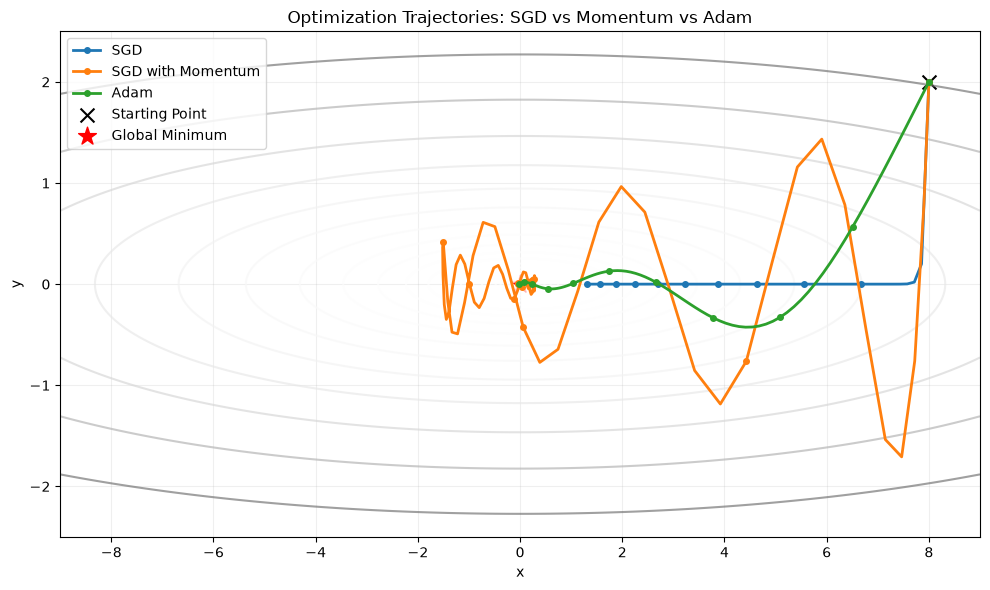

In [52]:

# Create coordinate grid
x = np.linspace(-9, 9, 400)
y = np.linspace(-2.5, 2.5, 400)

X_grid, Y_grid = np.meshgrid(x, y)

# Objective values over grid
Z_grid = 0.5 * (X_grid**2 + 50 * Y_grid**2)

plt.figure(figsize=(10, 6))

# Objective contours
levels = np.geomspace(0.02, 200, 22)

contours = plt.contour(
    X_grid,
    Y_grid,
    Z_grid,
    levels=levels,
    cmap="Greys",
    alpha=0.65
)

# Overlay optimizer trajectories
for name, traj in trajectories.items():

    plt.plot(
        traj[:, 0],
        traj[:, 1],
        marker="o",
        markevery=10,
        markersize=4,
        linewidth=2,
        label=name
    )

# Starting point
plt.scatter(
    start[0], start[1],
    marker="x",
    s=100,
    color="black",
    label="Starting Point"
)

# Global minimum
plt.scatter(
    0, 0,
    marker="*",
    s=180,
    color="red",
    label="Global Minimum"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    "Optimization Trajectories: SGD vs Momentum vs Adam"
)

plt.xlim(-9, 9)
plt.ylim(-2.5, 2.5)

plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()



### 4. Objective Value vs. Optimization Steps

The objective value is plotted against the number of optimization steps for each method.

A logarithmic scale is used to visualize differences in convergence behavior, especially when the objective values become very small.

This plot complements the contour visualization by illustrating the reduction in the objective function during optimization.


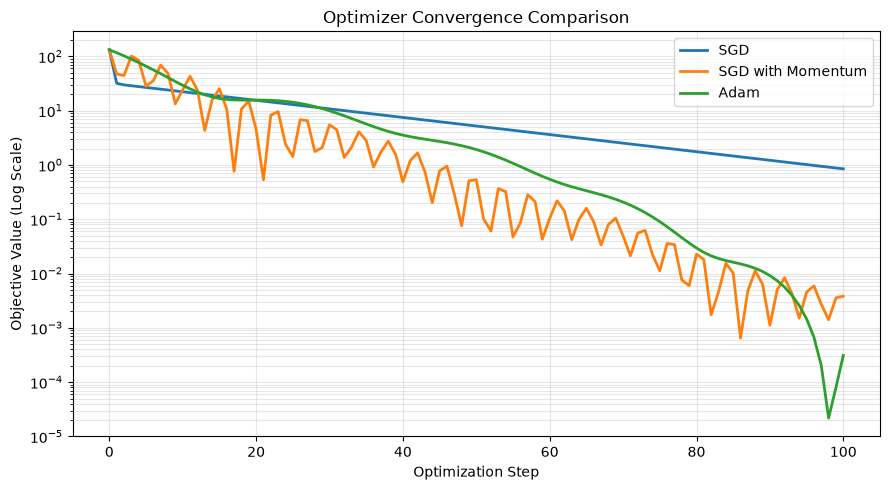

In [53]:

plt.figure(figsize=(9, 5))

for name, losses in loss_histories.items():

    plt.semilogy(
        range(len(losses)),
        np.maximum(losses, 1e-12),
        linewidth=2,
        label=name
    )

plt.xlabel("Optimization Step")
plt.ylabel("Objective Value (Log Scale)")
plt.title("Optimizer Convergence Comparison")

plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()


In [54]:
print(f"{'Optimizer':<20} {'Final Objective':>20}")
print("-" * 42)

for name, losses in loss_histories.items():
    print(f"{name:<20} {losses[-1]:>20.8f}")

Optimizer                 Final Objective
------------------------------------------
SGD                            0.84615034
SGD with Momentum              0.00383000
Adam                           0.00031029



### 5. Experimental Results and Discussion

The optimization trajectories of SGD, SGD with Momentum, and Adam were investigated using the quadratic objective function:

$$
f(x,y)=\frac{1}{2}(x^2+50y^2)
$$

All three optimizers were initialized at $(8,2)$, with an initial objective value of **132**, and performed **100 parameter updates**. The contour plot illustrates their optimization trajectories, while the objective-value plot demonstrates their convergence behavior.

#### SGD

Plain SGD initially moves rapidly toward the x-axis because the objective function has significantly greater curvature in the y-direction.

However, after reducing the y-coordinate, SGD progresses slowly along the flatter x-direction. This results in relatively slow convergence compared with the other two optimizers.

The final position was approximately $(1.30088, 0)$, with a final objective value of **0.84615034**.

#### SGD with Momentum

SGD with Momentum exhibits noticeable oscillations around the minimum, particularly along the steep y-direction.

These oscillations occur because momentum incorporates previous gradients, allowing the optimizer to continue moving even when the gradient direction changes.

Although the objective value fluctuates during optimization, the oscillations gradually decrease, allowing the optimizer to approach the minimum more closely than plain SGD.

The final position was approximately $(-0.04537, 0.01058)$, with a final objective value of **0.00383000**.

#### Adam

Adam follows a comparatively balanced trajectory toward the minimum by adaptively scaling parameter updates using bias-corrected first- and second-moment estimates.

The objective value generally decreases over successive optimization steps, although small fluctuations are observed near the end.

The final position was approximately $(-0.01483, -0.00283)$, with a final objective value of **0.00031029**.

#### Comparison of Final Objective Values

| Optimizer | Learning Rate | Final Objective Value |
|---|---:|---:|
| SGD | 0.018 | 0.84615034 |
| SGD with Momentum | 0.012 | 0.00383000 |
| Adam | 0.15 | **0.00031029** |

The results demonstrate three distinct convergence behaviors:

- **SGD:** Slow convergence along the low-curvature direction.
- **SGD with Momentum:** Faster overall progress, but with oscillations caused by accumulated momentum.
- **Adam:** Adaptive coordinate-wise updates, resulting in a more balanced trajectory and the lowest final objective value.

Different learning rates were used for the three optimizers. Therefore, the results demonstrate their behavior under the selected hyperparameters rather than establishing that one optimizer is universally faster.

### 6. Conclusion

The experiment demonstrates how optimizer update rules influence convergence on an objective function with different curvatures along its coordinate directions.

Plain SGD converges slowly along the flatter direction, while SGD with Momentum accelerates progress but introduces oscillations. Adam adapts the effective update magnitude for each coordinate and achieves the lowest final objective value of **0.00031029** under the tested settings.

These findings highlight the importance of momentum, adaptive learning rates, and hyperparameter selection in optimization performance.


**(c)** Train a small CNN with each optimizer (plain SGD, SGD with momentum, Adam) at three learning rates each. Plot validation accuracy versus learning rate and the training loss at the best rate. Discuss sensitivity.


### 1. Small CNN Architecture

A small Convolutional Neural Network (CNN) is constructed for CIFAR-10 classification. The network contains two convolutional layers with ReLU activations and max-pooling, followed by two fully connected layers.

The first convolutional layer extracts 32 feature maps, while the second produces 64 feature maps. The resulting features are flattened and passed through a hidden layer containing 64 neurons before producing 10 output logits.

The same architecture and initialization are used for every optimizer configuration to ensure a fair comparison.


In [55]:

import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

seed = 42
batch_size = 128
num_epochs = 8

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Check model architecture
model_check = SmallCNN().to(device)

num_params = sum(
    p.numel() for p in model_check.parameters()
)

print("Device:", device)
print("Trainable parameters:", num_params)

# Check output dimensions
dummy_input = torch.randn(2, 3, 32, 32).to(device)

with torch.no_grad():
    dummy_output = model_check(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

del model_check, dummy_input, dummy_output


Device: cuda
Trainable parameters: 282250
Input shape: torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 10])



### 2. Optimizer and Learning Rate Configuration

Three optimizers are evaluated: plain SGD, SGD with Momentum, and Adam. The custom Momentum and Adam implementations verified in Task 2(a) are reused.

Three learning rates are selected for each optimizer to investigate learning-rate sensitivity. A total of nine training experiments are performed under identical model architectures, dataset splits, batch sizes, and training durations.

The experiments use a fixed seed of 42, a mini-batch size of 128, and 8 training epochs per configuration.


In [56]:

# Learning rates for each optimizer
learning_rates = {
    "SGD": [0.001, 0.01, 0.1],
    "SGD with Momentum": [0.001, 0.01, 0.05],
    "Adam": [0.0001, 0.001, 0.01]
}

def create_optimizer(name, model, lr):

    if name == "SGD":
        return torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.0
        )

    elif name == "SGD with Momentum":
        return SGDMomentumCustom(
            model.parameters(),
            lr=lr,
            momentum=0.9
        )

    elif name == "Adam":
        return AdamCustom(
            model.parameters(),
            lr=lr,
            betas=(0.9, 0.999),
            eps=1e-8
        )

    else:
        raise ValueError("Unknown optimizer")


for name, rates in learning_rates.items():
    print(f"{name}: {rates}")


SGD: [0.001, 0.01, 0.1]
SGD with Momentum: [0.001, 0.01, 0.05]
Adam: [0.0001, 0.001, 0.01]



### 3. CNN Training and Validation Procedure

For each optimizer and learning-rate configuration, an independently initialized CNN is trained for 8 epochs.

During each epoch, mini-batch forward propagation computes the cross-entropy loss, PyTorch autograd calculates parameter gradients, and the selected optimizer updates the network parameters.

After each epoch, validation accuracy is measured on the 5,000 held-out validation images without performing gradient updates.

The training loss and validation accuracy are recorded for every experiment. The training data order and model initialization are controlled using a fixed random seed to improve comparability.


In [57]:

def train_cnn_experiment(optimizer_name, lr):

    # Reset random seed for a fair comparison
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # New CNN with identical initialization
    model = SmallCNN().to(device)

    # Select optimizer
    optimizer = create_optimizer(
        optimizer_name, model, lr
    )

    criterion = nn.CrossEntropyLoss()

    # Recreate loader with the same shuffling seed
    run_train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        generator=torch.Generator().manual_seed(seed)
    )

    train_history = []
    val_history = []

    for epoch in range(num_epochs):

        # -------- TRAINING --------
        model.train()

        total_loss = 0.0
        total_samples = 0

        progress = tqdm(
            run_train_loader,
            desc=f"{optimizer_name} | lr={lr} | Epoch {epoch+1}",
            leave=False
        )

        for images, labels in progress:

            images = images.to(device)
            labels = labels.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Automatic backward pass
            loss.backward()

            # Parameter update
            optimizer.step()

            # Accumulate sample-weighted loss
            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

            progress.set_postfix(
                loss=f"{total_loss/total_samples:.4f}"
            )

        epoch_loss = total_loss / total_samples
        train_history.append(epoch_loss)

        # -------- VALIDATION --------
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                predictions = outputs.argmax(dim=1)

                correct += (
                    predictions == labels
                ).sum().item()

                total += labels.size(0)

        val_acc = 100.0 * correct / total
        val_history.append(val_acc)

        print(
            f"{optimizer_name:<18} | "
            f"LR={lr:<7g} | "
            f"Epoch {epoch+1:02d}/{num_epochs} | "
            f"Loss={epoch_loss:.4f} | "
            f"Val Acc={val_acc:.2f}%"
        )

    return {
        "train_losses": train_history,
        "val_accuracies": val_history
    }



### 4. Learning Rate Experiments

Each optimizer is trained using three different learning rates, resulting in nine CNN training experiments.

The final validation accuracy and training loss are recorded for each configuration. These results are used to evaluate sensitivity to the learning rate and identify the best-performing learning rate for each optimizer.

The best learning rate is selected based on the validation accuracy at the end of the fixed 8-epoch training period.


In [58]:

results = {}

total_experiments = sum(
    len(rates) for rates in learning_rates.values()
)

experiment_number = 0

for optimizer_name, rates in learning_rates.items():

    for lr in rates:

        experiment_number += 1

        print(
            f"\n{'='*65}\n"
            f"Experiment {experiment_number}/{total_experiments}: "
            f"{optimizer_name}, LR={lr}\n"
            f"{'='*65}"
        )

        history = train_cnn_experiment(
            optimizer_name, lr
        )

        results[(optimizer_name, lr)] = history


print("\nAll nine experiments completed!")



Experiment 1/9: SGD, LR=0.001


SGD | lr=0.001 | Epoch 1:   0%|          | 0/352 [00:00<?, ?it/s]

SGD                | LR=0.001   | Epoch 01/8 | Loss=2.2905 | Val Acc=11.84%


SGD | lr=0.001 | Epoch 2:   0%|          | 0/352 [00:00<?, ?it/s]

SGD                | LR=0.001   | Epoch 02/8 | Loss=2.2607 | Val Acc=16.74%


...

Adam               | LR=0.01    | Epoch 06/8 | Loss=1.3761 | Val Acc=49.18%


Adam | lr=0.01 | Epoch 7:   0%|          | 0/352 [00:00<?, ?it/s]

Adam               | LR=0.01    | Epoch 07/8 | Loss=1.3485 | Val Acc=50.58%


Adam | lr=0.01 | Epoch 8:   0%|          | 0/352 [00:00<?, ?it/s]

Adam               | LR=0.01    | Epoch 08/8 | Loss=1.3348 | Val Acc=49.92%

All nine experiments completed!


In [59]:

print(
    f"{'Optimizer':<20} "
    f"{'LR':>10} "
    f"{'Final Loss':>14} "
    f"{'Final Val Acc':>16} "
    f"{'Best Val Acc':>15}"
)

print("-" * 80)

for (name, lr), history in results.items():

    final_loss = history["train_losses"][-1]
    final_acc = history["val_accuracies"][-1]
    best_acc = max(history["val_accuracies"])

    print(
        f"{name:<20} "
        f"{lr:>10.4g} "
        f"{final_loss:>14.4f} "
        f"{final_acc:>15.2f}% "
        f"{best_acc:>14.2f}%"
    )


Optimizer                    LR     Final Loss    Final Val Acc    Best Val Acc
--------------------------------------------------------------------------------
SGD                       0.001         1.9125           34.10%          34.10%
SGD                        0.01         1.1765           56.16%          57.14%
SGD                         0.1         0.5571           65.40%          71.06%
SGD with Momentum         0.001         1.1636           57.62%          57.62%
SGD with Momentum          0.01         0.5295           71.18%          71.92%
SGD with Momentum          0.05         0.4399           66.76%          68.96%
Adam                     0.0001         1.0903           60.18%          60.18%
Adam                      0.001         0.5924           71.00%          71.78%
Adam                       0.01         1.3348           49.92%          50.58%



### 5. Validation Accuracy vs. Learning Rate

The final validation accuracy after 8 epochs is plotted against the learning rate for each optimizer.

The learning-rate axis is displayed on a logarithmic scale to compare different orders of magnitude. The resulting curves illustrate how sensitive each optimizer is to the selected learning rate.

The best learning rate for each optimizer is identified as the value that achieves the highest final validation accuracy among its three tested configurations.


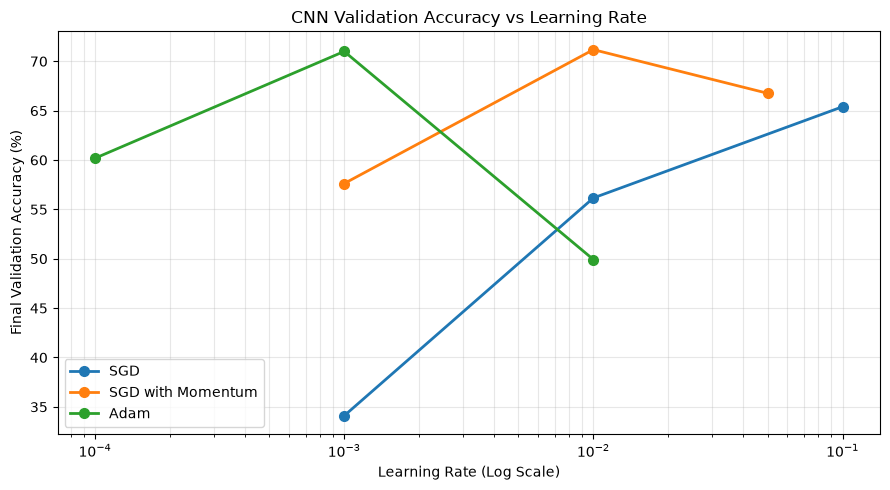

Best Learning Rates:
SGD                  | Best LR: 0.1      | Validation Accuracy: 65.40%
SGD with Momentum    | Best LR: 0.01     | Validation Accuracy: 71.18%
Adam                 | Best LR: 0.001    | Validation Accuracy: 71.00%


In [60]:

plt.figure(figsize=(9, 5))

best_rates = {}

for name, rates in learning_rates.items():

    accuracies = [
        results[(name, lr)]["val_accuracies"][-1]
        for lr in rates
    ]

    # Determine best LR using final validation accuracy
    best_idx = np.argmax(accuracies)
    best_rates[name] = rates[best_idx]

    plt.plot(
        rates,
        accuracies,
        marker="o",
        linewidth=2,
        markersize=7,
        label=name
    )

plt.xscale("log")

plt.xlabel("Learning Rate (Log Scale)")
plt.ylabel("Final Validation Accuracy (%)")
plt.title("CNN Validation Accuracy vs Learning Rate")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Best Learning Rates:")

for name, lr in best_rates.items():
    acc = results[(name, lr)]["val_accuracies"][-1]

    print(
        f"{name:<20} | "
        f"Best LR: {lr:<8g} | "
        f"Validation Accuracy: {acc:.2f}%"
    )



### 6. Training Loss at the Best Learning Rate

For each optimizer, the learning rate with the highest final validation accuracy is selected.

The corresponding training-loss curves are plotted against epochs to compare convergence behavior under the best tested learning-rate settings.

The curves are used to evaluate how quickly the optimizers reduce the training loss and whether their convergence behaviors differ.


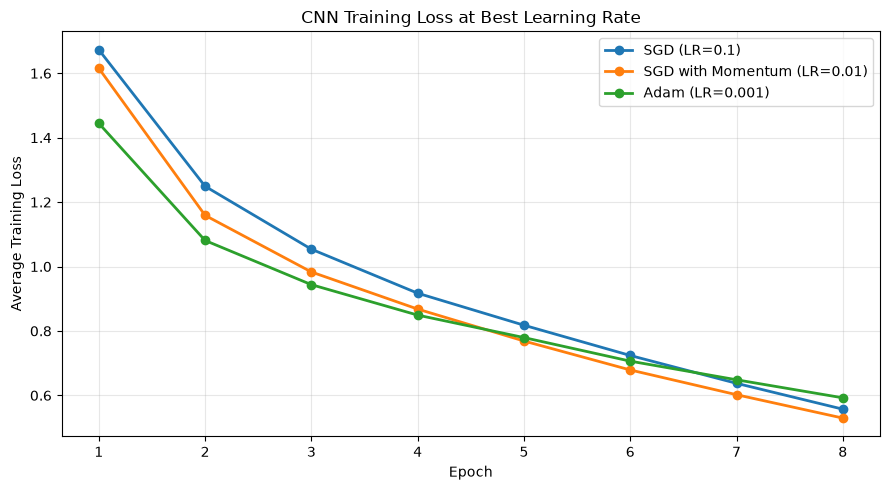

In [61]:

plt.figure(figsize=(9, 5))

for name, best_lr in best_rates.items():

    losses = results[
        (name, best_lr)
    ]["train_losses"]

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        marker="o",
        linewidth=2,
        label=f"{name} (LR={best_lr:g})"
    )

plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("CNN Training Loss at Best Learning Rate")

plt.xticks(range(1, num_epochs + 1))
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


### 7. Results and Sensitivity Discussion

| Optimizer | Learning rates | Final Val Acc (%) | Spread (pp) |
|---|---|---|---:|
| SGD | 0.001 / 0.01 / 0.1 | 34.10 / 56.16 / **65.40** | 31.3 |
| SGD with Momentum | 0.001 / 0.01 / 0.05 | 57.62 / **71.18** / 66.76 | 13.6 |
| Adam | 0.0001 / 0.001 / 0.01 | 60.18 / **71.00** / 49.92 | 21.1 |

- **Plain SGD** is the most sensitive: accuracy rises by 31 points from 0.001 to 0.1. Its best rate is the largest one tested, so the true optimum may lie higher. At 0.1 it is already unstable: validation accuracy peaks at 71.06% (epoch 6) and ends at 65.40%.
- **SGD with momentum** is the most robust (smallest spread) and gives the best accuracy. With $\mu=0.9$ the effective step is about $\eta/(1-\mu)=10\eta$, so its best rate of 0.01 matches the best plain-SGD rate of 0.1.
- **Adam** works well at its default rate of 0.001 but drops to 49.92% at 0.01, where the training loss stays at 1.33 because the steps are too large.
- **Training loss at the best rate:** Adam reduces the loss fastest at first (1.44 vs 1.67 for SGD after epoch 1), but SGD with momentum ends lowest (0.53).

**Conclusion:** with a well-chosen learning rate, SGD with momentum and Adam both reach about 71%. Plain SGD needs a much larger learning rate and is less stable. Results are from a single seed and 8 epochs.



## Task 3: Regularization and Residual Connections

### Task 3(a): Regularization

**Question:**

Train a small CNN with batch normalization on 5,000 training images. Compare the following regularization configurations:

1. Baseline
2. Weight Decay
3. Dropout
4. Flip + Crop
5. Cutout
6. Mixup
7. All Combined

Cutout and Mixup must be implemented manually.

**Requirements:**

- Tabulate the training accuracy, validation accuracy, and generalization gap for each configuration.
- Plot the training curves.
- Compare the results and explain the effects of the different regularization techniques.


### 1. Experimental Setup

The influence of regularization on CNN generalization is investigated using CIFAR-10.

A fixed subset of 5,000 images is selected from the original 45,000-image training partition. The existing 5,000-image validation partition is retained.

Seven regularization configurations are evaluated: Baseline, Weight Decay, Dropout, Flip + Crop, Cutout, Mixup, and All Combined.

All experiments use the same CNN architecture with batch normalization and the following training configuration:

| Hyperparameter | Value |
|---|---|
| Training samples | 5,000 |
| Validation samples | 5,000 |
| Optimizer | SGD with Momentum |
| Initial learning rate | 0.01 |
| Momentum | 0.9 |
| Batch size | 128 |
| Training epochs | 40 |
| Learning rate scheduler | Cosine Annealing |
| Minimum learning rate | 0.00001 |
| Random seed | 42 |

A cosine annealing scheduler is employed to gradually reduce the learning rate during training:

$$
\eta_t=\eta_{\min}
+\frac{1}{2}(\eta_{\max}-\eta_{\min})
\left(1+\cos\left(\frac{\pi t}{T_{\max}}\right)\right)
$$

where $t$ is the current epoch and $T_{\max}=40$.

The extended training duration provides additional optimization steps for strongly regularized configurations, while the learning-rate schedule reduces the update magnitude toward the end of training.

Training accuracy is evaluated on the original, unaugmented training subset to ensure a consistent generalization-gap comparison.

In [18]:

import random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, Subset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

SEED = 42
BATCH_SIZE = 128
EPOCHS = 40
LR = 0.01
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


generator = torch.Generator().manual_seed(SEED)

subset_indices = torch.randperm(
    len(train_dataset),
    generator=generator
)[:5000].tolist()

train_5k = Subset(train_dataset, subset_indices)

# Clean training loader for accuracy evaluation
train_clean_loader = DataLoader(
    train_5k,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# Unchanged validation partition
val_loader_3a = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Device:", DEVICE)
print("Training subset:", len(train_5k))
print("Validation samples:", len(val_dataset))


Device: cuda
Training subset: 5000
Validation samples: 5000



### 2. CNN Architecture with Batch Normalization

A small CNN containing two convolutional layers, batch normalization, ReLU activations, max-pooling, and two fully connected layers is used for CIFAR-10 classification.

Batch normalization is included in every experiment. Dropout is applied only in the configurations where it is required.

The model architecture is otherwise kept identical across all seven experiments to isolate the effects of regularization.


In [19]:

class RegularizedCNN(nn.Module):

    def __init__(self, dropout_p=0.0):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 64),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model_check = RegularizedCNN().to(DEVICE)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model_check.parameters())
)

with torch.no_grad():
    dummy = torch.randn(2, 3, 32, 32, device=DEVICE)
    print("Output shape:", model_check(dummy).shape)

del model_check, dummy


Trainable parameters: 282442
Output shape: torch.Size([2, 10])



### 3. Implementation of Regularization Techniques

The following techniques are evaluated:

- **Weight Decay:** L2 regularization using a weight decay coefficient of 0.0005.
- **Dropout:** Randomly disables hidden activations with probability 0.5 during training.
- **Flip + Crop:** Applies random horizontal flipping and random cropping with four-pixel reflection padding.
- **Cutout:** Removes a randomly located 16 × 16 region from each training image. The operation is implemented manually.
- **Mixup:** Creates interpolated training images and uses a weighted cross-entropy loss. The mixing operation is implemented manually with a Beta distribution parameter of 0.2.

The combined configuration applies all five techniques. All configurations include batch normalization.


In [21]:
class Cutout:
    def __init__(self, size=16):
        self.size = size

    def __call__(self, image):

        image = image.clone()
        _, height, width = image.shape

        cy = torch.randint(0, height, (1,)).item()
        cx = torch.randint(0, width, (1,)).item()

        half = self.size // 2

        y1 = max(0, cy - half)
        y2 = min(height, y1 + self.size)

        x1 = max(0, cx - half)
        x2 = min(width, x1 + self.size)
        image[:, y1:y2, x1:x2] = 0.0

        return image

In [22]:
class RegularizationDataset(Dataset):

    def __init__(
        self,
        base_dataset,
        flip_crop=False,
        cutout=False
    ):

        self.base_dataset = base_dataset

        self.flip_crop = flip_crop
        self.use_cutout = cutout

        self.augmentation = transforms.Compose([
            transforms.RandomCrop(
                32,
                padding=4,
                padding_mode="reflect"
            ),
            transforms.RandomHorizontalFlip(p=0.5)
        ])

        self.cutout_transform = Cutout(size=16)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):

        image, label = self.base_dataset[index]

        if self.flip_crop:
            image = self.augmentation(image)

        if self.use_cutout:
            image = self.cutout_transform(image)

        return image, label

In [23]:
def mixup_batch(images, labels, alpha=0.2):

    lam = np.random.beta(alpha, alpha)

    indices = torch.randperm(
        images.size(0),
        device=images.device
    )

    mixed_images = (
        lam * images
        + (1.0 - lam) * images[indices]
    )

    labels_a = labels
    labels_b = labels[indices]

    return mixed_images, labels_a, labels_b, lam


In [24]:

regularization_configs = {

    "Baseline": {
        "weight_decay": 0.0,
        "dropout": 0.0,
        "flip_crop": False,
        "cutout": False,
        "mixup": False
    },

    "Weight Decay": {
        "weight_decay": 5e-4,
        "dropout": 0.0,
        "flip_crop": False,
        "cutout": False,
        "mixup": False
    },

    "Dropout": {
        "weight_decay": 0.0,
        "dropout": 0.5,
        "flip_crop": False,
        "cutout": False,
        "mixup": False
    },

    "Flip + Crop": {
        "weight_decay": 0.0,
        "dropout": 0.0,
        "flip_crop": True,
        "cutout": False,
        "mixup": False
    },

    "Cutout": {
        "weight_decay": 0.0,
        "dropout": 0.0,
        "flip_crop": False,
        "cutout": True,
        "mixup": False
    },

    "Mixup": {
        "weight_decay": 0.0,
        "dropout": 0.0,
        "flip_crop": False,
        "cutout": False,
        "mixup": True
    },

    "All Combined": {
        "weight_decay": 5e-4,
        "dropout": 0.5,
        "flip_crop": True,
        "cutout": True,
        "mixup": True
    }
}

print("Number of experiments:", len(regularization_configs))


Number of experiments: 7


### 4. Training and Evaluation Procedure

Each regularization configuration is trained for 40 epochs using SGD with momentum. The learning rate follows a cosine annealing schedule from 0.01 to 0.00001, and `scheduler.step()` is called once at the end of every epoch.

All experiments use the same initial model weights and the same 5,000-image training subset. The random seed is reset before each experiment to improve reproducibility.

During training, the selected augmentations and regularization methods are applied. For Mixup, a weighted cross-entropy loss is calculated using the two original labels.

After each epoch, training accuracy is evaluated on the clean, unaugmented training subset, while validation accuracy is evaluated on the separate validation partition. Both evaluations use `model.eval()` to disable dropout and use batch normalization's running statistics.

The generalization gap is calculated as:

$$
\text{Generalization Gap}
=
\text{Training Accuracy}
-
\text{Validation Accuracy}
$$

In [29]:

@torch.no_grad()
def evaluate_accuracy(model, loader):

    model.eval()

    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100.0 * correct / total


In [30]:

def train_regularization_experiment(name, config):

    # Reproducible initialization
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Model with configurable dropout
    model = RegularizedCNN(
        dropout_p=config["dropout"]
    ).to(DEVICE)

    # Same optimizer except weight decay
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LR,
        momentum=0.9,
        weight_decay=config["weight_decay"]
    )

    # Cosine annealing learning-rate scheduler
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS,
        eta_min=1e-5
    )

    criterion = nn.CrossEntropyLoss()

    # Training data with selected augmentations
    augmented_dataset = RegularizationDataset(
        train_5k,
        flip_crop=config["flip_crop"],
        cutout=config["cutout"]
    )

    train_loader_run = DataLoader(
        augmented_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda"),
        generator=torch.Generator().manual_seed(SEED)
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0
        total_samples = 0

        for images, labels in train_loader_run:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            # Apply Mixup if enabled
            if config["mixup"]:

                images, ya, yb, lam = mixup_batch(
                    images, labels, alpha=0.2
                )

                outputs = model(images)

                loss = (
                    lam * criterion(outputs, ya)
                    + (1 - lam) * criterion(outputs, yb)
                )

            else:
                outputs = model(images)
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

        epoch_loss = running_loss / total_samples

        # Evaluate on CLEAN training images
        train_acc = evaluate_accuracy(
            model, train_clean_loader
        )

        # Evaluate on validation images
        val_acc = evaluate_accuracy(
            model, val_loader_3a
        )

        history["train_loss"].append(epoch_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # Update learning rate after completing the epoch
        scheduler.step()

        if (epoch + 1) == 1 or (epoch + 1) % 5 == 0:
            print(
                f"{name:<15} | "
                f"Epoch {epoch+1:02d}/{EPOCHS} | "
                f"Loss: {epoch_loss:.4f} | "
                f"Train: {train_acc:.2f}% | "
                f"Val: {val_acc:.2f}%"
            )

    return history


In [31]:

reg_results = {}

for name, config in tqdm(
    regularization_configs.items(),
    total=len(regularization_configs),
    desc="Regularization Experiments"
):

    print(f"\n{'='*60}")
    print("Running:", name)
    print(f"{'='*60}")

    history = train_regularization_experiment(
        name, config
    )

    reg_results[name] = history

print("\nAll seven experiments completed.")


Regularization Experiments:   0%|          | 0/7 [00:00<?, ?it/s]


Running: Baseline
Baseline        | Epoch 01/40 | Loss: 1.8401 | Train: 34.44% | Val: 31.26%
Baseline        | Epoch 05/40 | Loss: 1.0750 | Train: 65.24% | Val: 53.06%
Baseline        | Epoch 10/40 | Loss: 0.6813 | Train: 80.34% | Val: 55.12%
Baseline        | Epoch 15/40 | Loss: 0.2664 | Train: 85.52% | Val: 55.18%
Baseline        | Epoch 20/40 | Loss: 0.0889 | Train: 99.20% | Val: 59.08%
Baseline        | Epoch 25/40 | Loss: 0.0390 | Train: 100.00% | Val: 60.20%
Baseline        | Epoch 30/40 | Loss: 0.0227 | Train: 100.00% | Val: 60.34%
Baseline        | Epoch 35/40 | Loss: 0.0216 | Train: 100.00% | Val: 60.20%
Baseline        | Epoch 40/40 | Loss: 0.0186 | Train: 100.00% | Val: 60.24%

Running: Weight Decay
Weight Decay    | Epoch 01/40 | Loss: 1.8389 | Train: 34.96% | Val: 31.92%
Weight Decay    | Epoch 05/40 | Loss: 1.0430 | Train: 66.84% | Val: 53.38%
Weight Decay    | Epoch 10/40 | Loss: 0.6202 | Train: 82.42% | Val: 55.74%
Weight Decay    | Epoch 15/40 | Loss: 0.2750 | Train: 

### 5. Regularization Comparison Results

The seven regularization configurations are compared using the final training accuracy, validation accuracy, and generalization gap after 40 epochs.

Training accuracy is measured on the original 5,000 training images without augmentation. The generalization gap is reported in percentage points.

The best validation accuracy, the epoch at which it occurred, and the mean validation accuracy over the last five epochs are also reported, since a single final-epoch value can be affected by epoch-to-epoch fluctuations.

A smaller positive gap generally indicates less overfitting, although validation accuracy must also be considered when comparing configurations.

In [33]:
import pandas as pd

summary = []

for name, history in reg_results.items():

    train_acc = history["train_acc"][-1]
    val_acc = history["val_acc"][-1]
    gap = train_acc - val_acc

    best_val = max(history["val_acc"])
    best_epoch = history["val_acc"].index(best_val) + 1

    summary.append({
        "Configuration": name,
        "Train Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc,
        "Gap (pp)": gap,
        "Best Val Accuracy (%)": best_val,
        "Best Epoch": best_epoch,
        "Mean Val, Last 5 (%)": np.mean(history["val_acc"][-5:])
    })

summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(
    by="Validation Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

Configuration  Train Accuracy (%)  Validation Accuracy (%)  Gap (pp)  Best Val Accuracy (%)  Best Epoch  Mean Val, Last 5 (%)
  Flip + Crop               78.74                    67.60     11.14                  67.62          39                 67.46
       Cutout               96.48                    62.36     34.12                  62.66          36                 62.52
      Dropout               89.20                    61.30     27.90                  61.46          39                 61.28
 Weight Decay              100.00                    60.70     39.30                  60.94          35                 60.64
     Baseline              100.00                    60.24     39.76                  60.40          22                 60.19
        Mixup               99.86                    60.18     39.68                  61.34          29                 60.50
 All Combined               57.18                    53.88      3.30                  54.56          37               

### 6. Training Curves

Five figures are produced. Each configuration uses the same colour in every figure.

1. **Training loss** for all seven configurations.
2. **Validation accuracy** for all seven configurations.
3. **Clean training accuracy** for all seven configurations.
4. **Training versus validation accuracy for each configuration**, with the shaded region showing the generalization gap at every epoch.
5. **Final training accuracy, validation accuracy, and gap** as a bar chart.

The Mixup and All Combined configurations optimize a weighted cross-entropy objective on interpolated images and labels. Therefore, their training losses are not directly equivalent to the standard cross-entropy losses used by the other configurations. Validation accuracy and the clean-training generalization gap provide more comparable measures of regularization effectiveness.

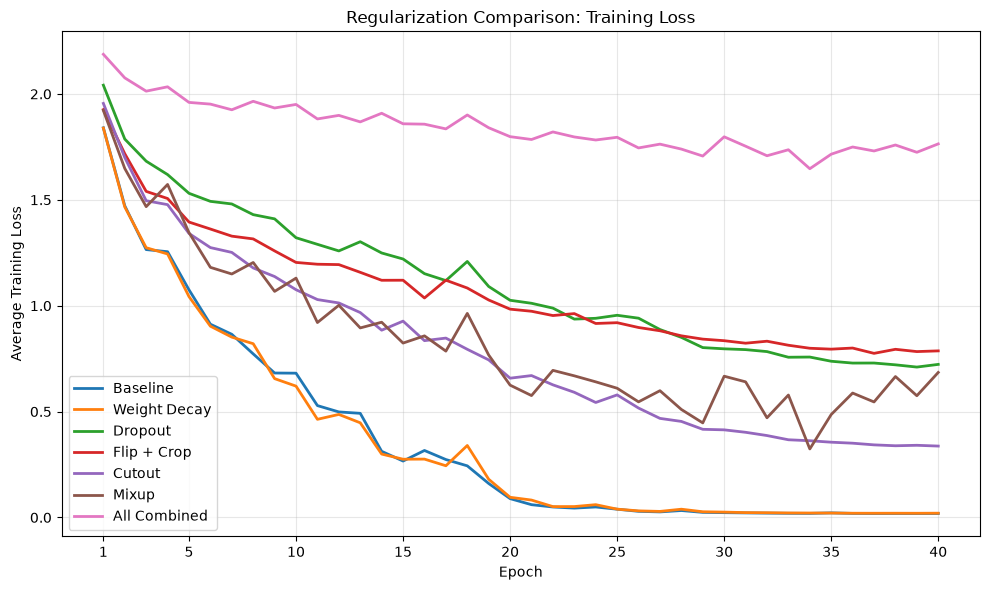

In [34]:
# One fixed colour per configuration, reused in every figure
REG_COLORS = {
    name: plt.cm.tab10(k)
    for k, name in enumerate(regularization_configs)
}

plt.figure(figsize=(10, 6))

for name, history in reg_results.items():
    plt.plot(
        range(1, EPOCHS + 1),
        history["train_loss"],
        linewidth=2,
        color=REG_COLORS[name],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Average Training Loss")
plt.title("Regularization Comparison: Training Loss")
plt.xticks([1] + list(range(5, EPOCHS + 1, 5)))

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

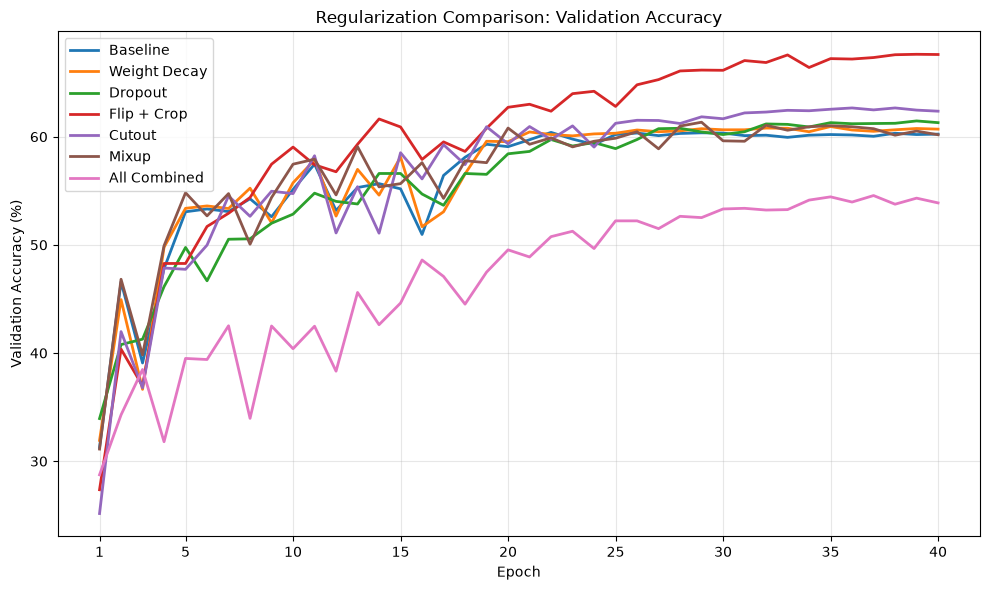

In [35]:
plt.figure(figsize=(10, 6))

for name, history in reg_results.items():
    plt.plot(
        range(1, EPOCHS + 1),
        history["val_acc"],
        linewidth=2,
        color=REG_COLORS[name],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Regularization Comparison: Validation Accuracy")
plt.xticks([1] + list(range(5, EPOCHS + 1, 5)))

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

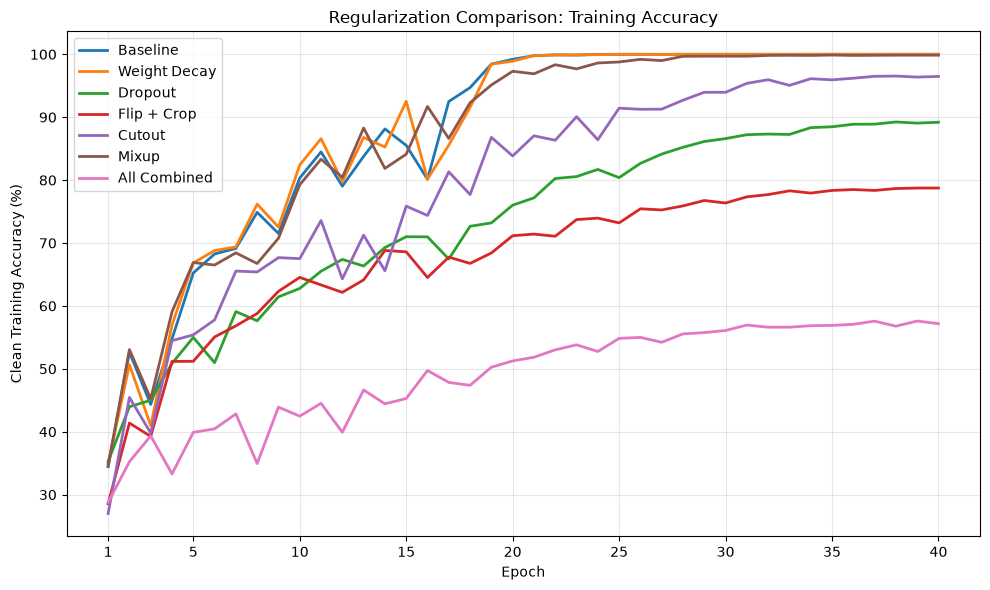

In [36]:
plt.figure(figsize=(10, 6))

for name, history in reg_results.items():
    plt.plot(
        range(1, EPOCHS + 1),
        history["train_acc"],
        linewidth=2,
        color=REG_COLORS[name],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Clean Training Accuracy (%)")
plt.title("Regularization Comparison: Training Accuracy")
plt.xticks([1] + list(range(5, EPOCHS + 1, 5)))

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

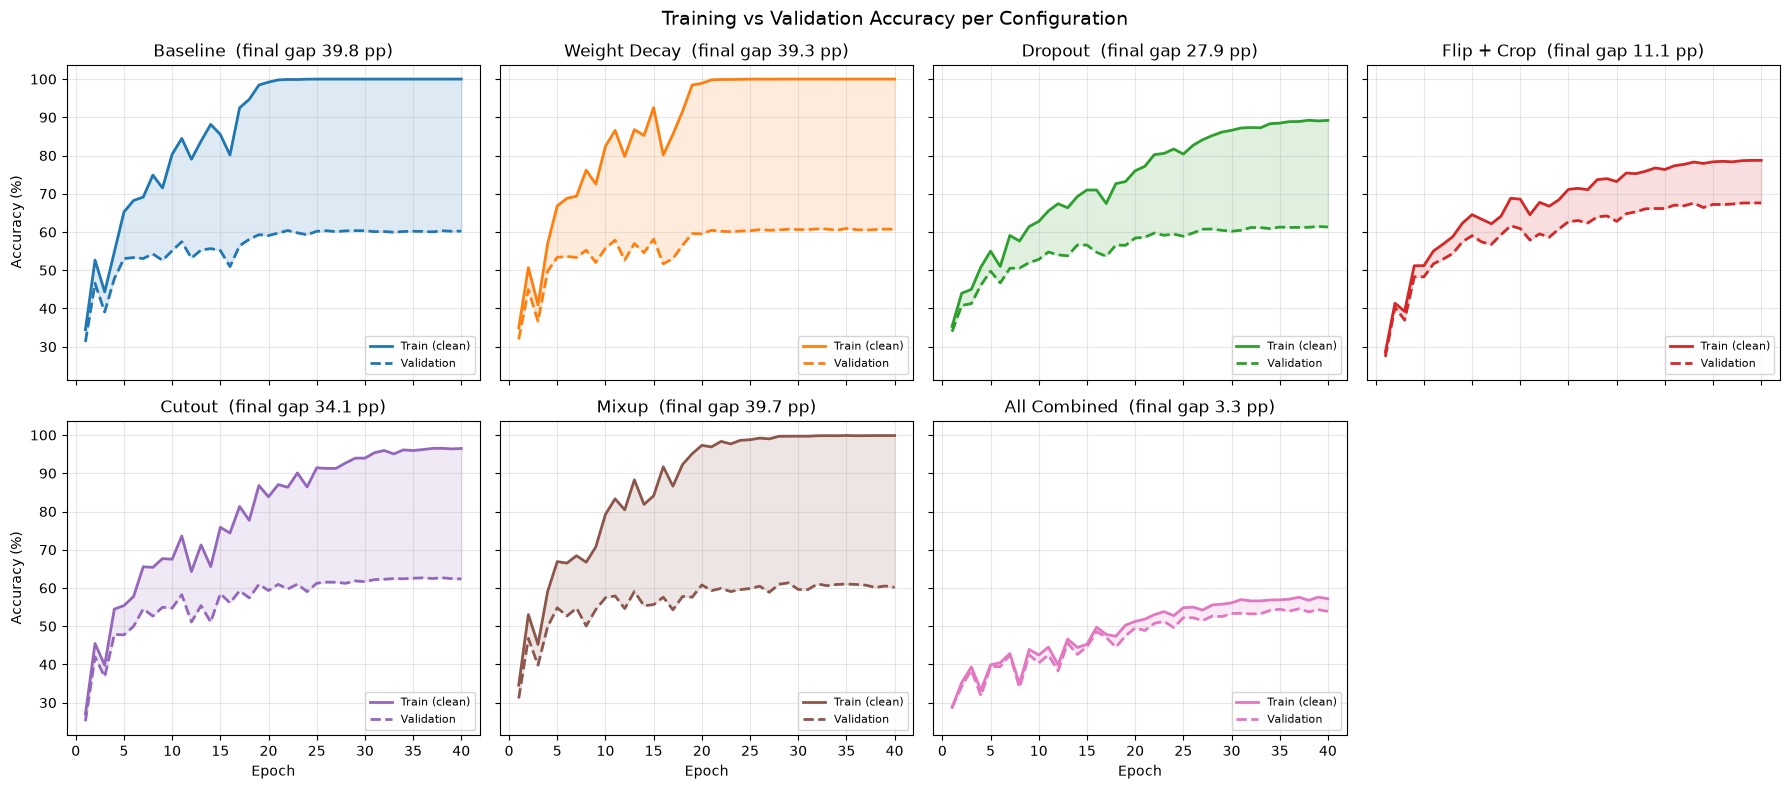

In [37]:
# Training vs validation accuracy for each configuration; shaded area = generalization gap
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
epochs = range(1, EPOCHS + 1)

for ax, (name, history) in zip(axes.flat, reg_results.items()):

    color = REG_COLORS[name]
    gap = history["train_acc"][-1] - history["val_acc"][-1]

    ax.plot(epochs, history["train_acc"], color=color, linewidth=2, label="Train (clean)")
    ax.plot(epochs, history["val_acc"], color=color, linewidth=2, linestyle="--", label="Validation")
    ax.fill_between(epochs, history["val_acc"], history["train_acc"], color=color, alpha=0.15)

    ax.set_title(f"{name}  (final gap {gap:.1f} pp)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right", fontsize=8)

# Hide the unused eighth panel
axes.flat[-1].axis("off")

for ax in axes[1]:
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("Accuracy (%)")

fig.suptitle("Training vs Validation Accuracy per Configuration", fontsize=14)
plt.tight_layout()
plt.show()

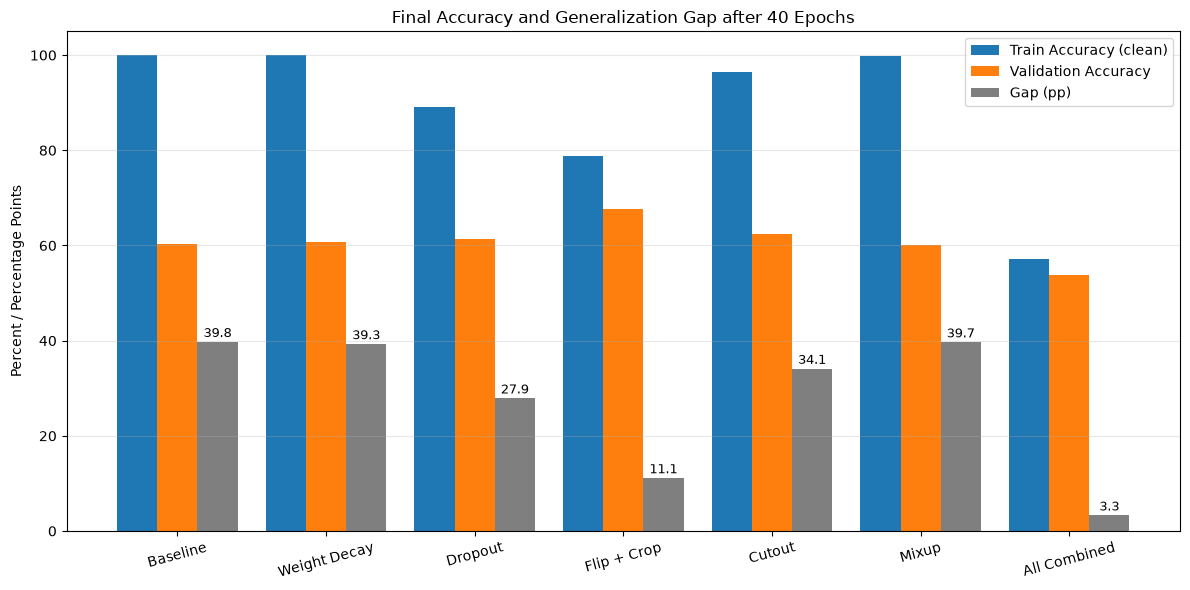

In [38]:
# Final training accuracy, validation accuracy, and gap per configuration
names = list(reg_results)
final_train = [reg_results[n]["train_acc"][-1] for n in names]
final_val = [reg_results[n]["val_acc"][-1] for n in names]
final_gap = [t - v for t, v in zip(final_train, final_val)]

x = np.arange(len(names))
width = 0.27

plt.figure(figsize=(12, 6))

plt.bar(x - width, final_train, width, label="Train Accuracy (clean)", color="tab:blue")
plt.bar(x, final_val, width, label="Validation Accuracy", color="tab:orange")
bars = plt.bar(x + width, final_gap, width, label="Gap (pp)", color="tab:gray")

for bar, gap in zip(bars, final_gap):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{gap:.1f}",
        ha="center",
        fontsize=9
    )

plt.xticks(x, names, rotation=15)
plt.ylabel("Percent / Percentage Points")
plt.title(f"Final Accuracy and Generalization Gap after {EPOCHS} Epochs")

plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 7. Experimental Results and Discussion

Seven regularization configurations were evaluated using a CNN with batch normalization trained on **5,000 CIFAR-10 images** for **40 epochs** with cosine learning-rate annealing. The same CNN architecture, optimizer, initial learning rate, and validation dataset were used for all configurations.

Training accuracy was evaluated using the original, unaugmented training images, while validation accuracy was measured on a separate set of 5,000 images.

#### 7.1 Regularization Comparison

The final training accuracy, validation accuracy, and generalization gap after 40 epochs are summarized below.

| Configuration | Training Accuracy (%) | Validation Accuracy (%) | Gap (pp) | Best Val Accuracy (%) |
|---|---:|---:|---:|---:|
| Baseline | 100.00 | 60.24 | 39.76 | 60.40 |
| Weight Decay | 100.00 | 60.70 | 39.30 | 60.94 |
| Dropout | 89.20 | 61.30 | 27.90 | 61.46 |
| Flip + Crop | 78.74 | **67.60** | 11.14 | **67.62** |
| Cutout | 96.48 | 62.36 | 34.12 | 62.66 |
| Mixup | 99.86 | 60.18 | 39.68 | 61.34 |
| All Combined | 57.18 | 53.88 | 3.30 | 54.56 |

#### 7.2 Analysis of Individual Techniques

**Baseline:** The baseline model reached **100% training accuracy** by epoch 25 and its training loss fell to **0.019**, so it memorized the 5,000 training images. Its validation accuracy stopped improving at about **60%**, giving the largest gap of **39.76 percentage points**. This is clear overfitting: further training only fits the training set more closely without improving generalization.

**Weight Decay:** Weight decay ($5\times10^{-4}$) gave almost the same behaviour as the baseline: **100% training accuracy**, **60.70% validation accuracy**, and a gap of **39.30 percentage points**. The 0.46-point improvement is within the variation expected from a single run, so this coefficient had little measurable effect over 40 epochs.

**Dropout:** Dropout ($p=0.5$) slowed down fitting of the training set, reaching **89.20% training accuracy**, and improved validation accuracy to **61.30%**. The gap decreased to **27.90 percentage points**. With 20 epochs, dropout had appeared to hurt performance; with 40 epochs, it improves over the baseline, which shows that strongly regularized models need a longer training budget.

**Flip + Crop:** Random horizontal flipping and cropping was the most effective technique, achieving **67.60% validation accuracy**, **7.4 points above the baseline**, with a gap of only **11.14 percentage points**. Because every epoch shows the network new shifted and mirrored versions of the images, it cannot memorize the exact pixels and must learn features that are robust to position and orientation. Its validation accuracy was still increasing at the end of training, so it would likely benefit from even more epochs.

**Cutout:** Cutout achieved **62.36% validation accuracy**, about **2.1 points above the baseline**, while reducing the gap to **34.12 percentage points**. Masking a random 16×16 region forces the network to use several parts of the object rather than one discriminative region. However, the training accuracy of **96.48%** shows that the network can still largely memorize the training images.

**Mixup:** Mixup reached **99.86% training accuracy** and **60.18% validation accuracy**, which is no better than the baseline, and its gap of **39.68 percentage points** is almost the same. With $\alpha=0.2$, the mixing coefficient $\lambda$ drawn from $\text{Beta}(0.2, 0.2)$ is usually close to 0 or 1, so most mixed images are very similar to one of the original images. This makes the regularization weak. A larger value such as $\alpha=1.0$ would create stronger mixing. The Mixup training loss also fluctuates between epochs because $\lambda$ changes for every batch.

**All Combined:** Combining all techniques produced the smallest gap of **3.30 percentage points**, but also the lowest training accuracy (**57.18%**) and validation accuracy (**53.88%**). The training loss remained around **1.76** after 40 epochs. Although the extra epochs improved this configuration from 48.26% to 53.88% validation accuracy, it still underfits. The regularizers were combined at their individual strengths without re-tuning, and together they are too strong for a CNN with about 282k parameters trained on 5,000 images.

#### 7.3 Training Loss Analysis

The baseline and weight decay configurations reached the lowest training losses (about **0.02**), which is consistent with their 100% training accuracy and confirms memorization.

The augmentation-based methods (Flip + Crop and Cutout) and Dropout kept higher training losses because the network sees a harder, changing version of the training data at every epoch. Flip + Crop had one of the highest losses (**0.79**) and yet the best validation accuracy, which shows that a low training loss is not a good indicator of generalization.

The All Combined configuration maintained the highest training loss throughout training, supporting the observation of underfitting.

The training losses for Mixup and All Combined represent weighted cross-entropy on interpolated images and labels. Therefore, their loss values are not directly comparable with the standard cross-entropy losses of the other configurations.

#### 7.4 Training and Validation Accuracy Analysis

The per-configuration plots show the generalization gap as the shaded region between the training and validation curves. For the Baseline, Weight Decay, and Mixup configurations, this region widens as the training accuracy approaches 100% while the validation accuracy levels off near 60%.

For Flip + Crop, the two curves rise together and remain relatively close, which indicates that the improvement in training accuracy carries over to unseen images.

The cosine learning-rate schedule reduces the step size towards the end of training, so the curves become stable in the final epochs. For example, the baseline validation accuracy at epochs 25, 30, 35, and 40 stays between 60.20% and 60.34%. This makes the final-epoch values more reliable than with a constant learning rate.

Compared with the earlier run of 20 epochs at a constant learning rate, the longer cosine schedule mainly helped the strongly regularized configurations: Dropout improved from 54.12% to 61.30%, Flip + Crop from 61.78% to 67.60%, and All Combined from 48.26% to 53.88%. The baseline gained only 0.32 points because it had already memorized the training set by epoch 20.

All results come from a single random seed, so differences smaller than about one percentage point (for example, Baseline, Weight Decay, and Mixup) should not be considered significant.

Overall, **Flip + Crop was the most effective regularization configuration under the tested settings**, while combining all techniques resulted in excessive regularization.

### 8. Conclusion

The experiment investigated the effects of regularization on CNN generalization using a limited CIFAR-10 training dataset.

The baseline CNN overfitted strongly, reaching **100% training accuracy** but only **60.24% validation accuracy**.

Among the regularization configurations, **Flip + Crop achieved the best validation accuracy of 67.60%** with a small gap of 11.14 percentage points. Cutout and Dropout gave smaller improvements, while Weight Decay and Mixup (with $\alpha=0.2$) performed similarly to the baseline.

The All Combined configuration had the smallest gap but the lowest validation accuracy, which shows that a small generalization gap is only useful when it is achieved at a high accuracy.

The results demonstrate that effective regularization requires a balance between reducing overfitting and preserving the model's ability to learn useful features, and that strongly regularized models require a sufficiently long training budget.

### Task 3(b): Residual Connections

**Question:**

Build CIFAR-style plain and residual networks of depth $6n+2$ for depths 8, 20, and 56 (three stages, channels 16/32/64, global average pooling, batch norm, Kaiming initialization). The only difference between the two families is the shortcut. Plot the training loss versus epoch and explain.

**Requirements:**

- Build plain and residual networks of depth $6n+2$ for depths 8 ($n=1$), 20 ($n=3$), and 56 ($n=9$).
- Use three stages with 16, 32, and 64 channels, global average pooling, batch normalization, and Kaiming initialization.
- Keep both families identical except for the shortcut connections.
- Plot the training loss versus epoch and explain the results.


### 1. Objective

The objective is to investigate the degradation problem in deep neural networks and determine how residual connections influence optimization.

For a network of depth $6n+2$, each stage contains $n$ blocks, and each block contains two convolutional layers.

The six experimental configurations are:

| Network Depth | n | Plain Network | Residual Network |
|---|---|---|---|
| 8 | 1 | Plain-8 | ResNet-8 |
| 20 | 3 | Plain-20 | ResNet-20 |
| 56 | 9 | Plain-56 | ResNet-56 |

Both network families use identical convolutional architectures, batch normalization, global average pooling, and Kaiming initialization. The residual networks additionally perform shortcut addition.

The training-loss curves are compared to investigate whether increased depth makes plain networks harder to optimize and whether residual connections improve trainability.


### 2. Plain and Residual Block Implementation

Both network families use an identical two-layer convolutional block:

$$
F(x)=BN_2(Conv_2(ReLU(BN_1(Conv_1(x)))))
$$

For the plain network, the block output is:

$$
y=ReLU(F(x))
$$

For the residual network, the output is:

$$
y=ReLU(F(x)+h(x))
$$

where $h(x)$ is the identity shortcut when the dimensions match.

When spatial dimensions and channels change between stages, the shortcut uses stride-based subsampling and zero-padding (option A). This introduces no additional trainable parameters.

Therefore, the shortcut connection is the only architectural difference between the two network families.


In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class CIFARBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1,
        use_shortcut=False
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=False)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        self.stride = stride
        self.use_shortcut = use_shortcut

    def forward(self, x):

        # Same convolutional operations in both families
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # Only difference: residual shortcut
        if self.use_shortcut:

            shortcut = x

            # Downsample spatial dimensions
            if self.stride != 1:
                shortcut = shortcut[
                    :, :, ::self.stride, ::self.stride
                ]

            # Zero-pad additional channels (option A)
            if shortcut.shape[1] != out.shape[1]:

                extra_channels = (
                    out.shape[1] - shortcut.shape[1]
                )

                zeros = torch.zeros(
                    shortcut.size(0),
                    extra_channels,
                    shortcut.size(2),
                    shortcut.size(3),
                    device=shortcut.device,
                    dtype=shortcut.dtype
                )

                shortcut = torch.cat(
                    [shortcut, zeros],
                    dim=1
                )

            out = out + shortcut

        return self.relu(out)



### 3. CIFAR-Style Network Architecture

The plain and residual networks follow the CIFAR-style architecture proposed by He et al. (2016).

An initial $3\times3$ convolution produces 16 feature maps. Three subsequent stages contain 16, 32, and 64 channels, respectively.

Each stage contains $n$ two-convolution blocks. The first block in stages 2 and 3 performs spatial downsampling with stride 2.

The network ends with global average pooling and a fully connected classifier producing 10 class logits.

The total depth is:

$$
D=1+3(2n)+1=6n+2
$$

Kaiming initialization is applied to convolutional and fully connected layers. Batch normalization is included in both network families.

The same implementation is used for both families, controlled by a Boolean flag that enables or disables shortcut addition.


In [2]:

class CIFARNetwork(nn.Module):

    def __init__(self, depth=20, use_shortcuts=False):
        super().__init__()

        assert depth >= 8 and (depth - 2) % 6 == 0

        n = (depth - 2) // 6

        # Initial convolution
        self.stem = nn.Sequential(
            nn.Conv2d(
                3, 16, kernel_size=3,
                padding=1, bias=False
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=False)
        )

        # Three network stages
        self.stage1 = self.make_stage(
            16, 16, n, stride=1,
            use_shortcuts=use_shortcuts
        )

        self.stage2 = self.make_stage(
            16, 32, n, stride=2,
            use_shortcuts=use_shortcuts
        )

        self.stage3 = self.make_stage(
            32, 64, n, stride=2,
            use_shortcuts=use_shortcuts
        )

        # Classification head
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 10)

        # Kaiming initialization
        self.apply(self.initialize_weights)

    @staticmethod
    def make_stage(
        in_channels,
        out_channels,
        n,
        stride,
        use_shortcuts
    ):

        blocks = [
            CIFARBlock(
                in_channels,
                out_channels,
                stride=stride,
                use_shortcut=use_shortcuts
            )
        ]

        for _ in range(n - 1):
            blocks.append(
                CIFARBlock(
                    out_channels,
                    out_channels,
                    stride=1,
                    use_shortcut=use_shortcuts
                )
            )

        return nn.Sequential(*blocks)

    @staticmethod
    def initialize_weights(m):

        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(
                m.weight,
                mode="fan_out",
                nonlinearity="relu"
            )

        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

        elif isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(
                m.weight,
                mode="fan_in",
                nonlinearity="relu"
            )
            nn.init.zeros_(m.bias)

    def forward(self, x):

        x = self.stem(x)

        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)

        x = self.pool(x)
        x = torch.flatten(x, 1)

        return self.fc(x)


In [3]:

SEED_3B = 42

print(
    f"{'Depth':<8} "
    f"{'Actual Depth':<14} "
    f"{'Parameters':<14} "
    f"{'Same Init':<12}"
)
print("-" * 55)

for depth in [8, 20, 56]:

    # Identical initialization for both families
    torch.manual_seed(SEED_3B)
    plain = CIFARNetwork(depth, use_shortcuts=False)

    torch.manual_seed(SEED_3B)
    residual = CIFARNetwork(depth, use_shortcuts=True)

    actual_depth = (
        sum(
            isinstance(m, nn.Conv2d)
            for m in plain.modules()
        ) + 1
    )

    num_params = sum(
        p.numel() for p in plain.parameters()
    )

    # Check that every parameter and buffer starts equal
    same_init = all(
        torch.equal(
            plain.state_dict()[key],
            residual.state_dict()[key]
        )
        for key in plain.state_dict()
    )

    assert actual_depth == depth
    assert same_init

    assert num_params == sum(
        p.numel() for p in residual.parameters()
    )

    print(
        f"{depth:<8} "
        f"{actual_depth:<14} "
        f"{num_params:<14,} "
        f"{str(same_init):<12}"
    )

    del plain, residual


Depth    Actual Depth   Parameters     Same Init   
-------------------------------------------------------
8        8              75,290         True        
20       20             269,722        True        
56       56             853,018        True        


### 4. Training Configuration

All six networks are trained on the same 45,000-image CIFAR-10 training partition. The 5,000-image validation partition is used only to monitor accuracy and is never used for training.

The full 45k partition is used here, rather than the 5k subset from Task 3(a), because this experiment studies how easily networks of different depths can be **optimized**, not how well they generalize from limited data.

The following settings are kept fixed across experiments:

| Hyperparameter | Value |
|---|---|
| Training images | 45,000 |
| Validation images | 5,000 (monitoring only) |
| Batch size | 128 |
| Optimizer | SGD |
| Initial learning rate | 0.1 |
| Momentum | 0.9 |
| Weight decay | 0.0001 |
| Training epochs | 30 |
| Learning-rate schedule | Cosine annealing |
| Minimum learning rate | 0.0001 |
| Data augmentation | Random horizontal flip and crop (4-pixel reflection padding) |
| Initialization | Kaiming |
| Random seed | 42 |

Both network families use identical training settings, and matching-depth models begin with identical weights. The data order and augmentation are also identical, because the random seed is reset after each model is created.

The original paper trains for 64k iterations (about 182 epochs) with a step learning-rate schedule. Here, 30 epochs with cosine annealing are used so that all six networks can be trained within the time budget of a Colab T4 GPU. This is therefore a small-scale reproduction of the ResNet experiment.

To make training fast, the normalized training and validation images are stored once as tensors on the GPU, and random cropping and flipping are applied per image directly on the GPU for each mini-batch. This avoids the single-threaded CPU data loader, which would otherwise be the bottleneck.

In [9]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

DEVICE_3B = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE_3B = 128
EPOCHS_3B = 30
LR_3B = 0.1
MIN_LR_3B = 1e-4
WEIGHT_DECAY_3B = 1e-4
MID_EPOCH_3B = EPOCHS_3B // 2


def to_device_tensors(dataset, device):
    """Stack an already-normalized dataset into image and label tensors on the device."""

    loader = DataLoader(
        dataset,
        batch_size=1000,
        shuffle=False,
        num_workers=0
    )

    images, labels = [], []

    for x, y in loader:
        images.append(x)
        labels.append(y)

    return torch.cat(images).to(device), torch.cat(labels).to(device)


# Same 45k/5k partition and training-set normalization as Task 1, loaded once
X_train_3b, y_train_3b = to_device_tensors(train_dataset, DEVICE_3B)
X_val_3b, y_val_3b = to_device_tensors(val_dataset, DEVICE_3B)

assert X_train_3b.shape == (45000, 3, 32, 32)
assert X_val_3b.shape == (5000, 3, 32, 32)


def augment_batch_3b(images, padding=4):
    """Random crop with reflection padding and random horizontal flip, per image, on the GPU."""

    n, c, h, w = images.shape
    device = images.device

    padded = F.pad(
        images,
        (padding, padding, padding, padding),
        mode="reflect"
    )

    # Independent crop position for every image
    top = torch.randint(0, 2 * padding + 1, (n,), device=device)
    left = torch.randint(0, 2 * padding + 1, (n,), device=device)

    rows = (top[:, None] + torch.arange(h, device=device))[:, None, :, None]
    cols = (left[:, None] + torch.arange(w, device=device))[:, None, None, :]

    batch_idx = torch.arange(n, device=device)[:, None, None, None]
    channel_idx = torch.arange(c, device=device)[None, :, None, None]

    cropped = padded[batch_idx, channel_idx, rows, cols]

    # Flip each image horizontally with probability 0.5
    flip = torch.rand(n, device=device) < 0.5

    return torch.where(
        flip[:, None, None, None],
        cropped.flip(3),
        cropped
    )


print("Device:", DEVICE_3B)
print("Training samples:", len(X_train_3b))
print("Validation samples:", len(X_val_3b))
print("Epochs:", EPOCHS_3B)

Device: cuda
Training samples: 45000
Validation samples: 5000
Epochs: 30


### 5. Training Plain and Residual Networks

The three plain networks and three residual networks are trained independently using the same optimization settings.

Each experiment starts from a newly initialized model. For models of equal depth, identical initial weights are used to isolate the effect of shortcut connections.

The training loss of each epoch is the average cross-entropy over all augmented mini-batches of that epoch, computed in training mode:

$$
L_{\text{train}}=
\frac{1}{N}\sum_{i=1}^{N}
CE(f_\theta(x_i),y_i)
$$

The following quantities are recorded after every epoch:

- **Training loss** and **training accuracy** (running averages over the augmented mini-batches of the epoch).
- **Validation loss** and **validation accuracy** (evaluated in `model.eval()` mode on the 5,000 unaugmented validation images).

Validation accuracy is not required by the question, but it shows whether a higher training loss in deep plain networks also leads to worse performance on unseen images, which separates optimization difficulty from overfitting.

The results are saved to `task3b_histories.pt` after each network. If the notebook is interrupted, rerunning the training cell skips the networks that have already finished.

In [10]:
@torch.no_grad()
def evaluate_3b(model, images, labels, batch_size=1000):

    model.eval()

    total_loss = 0.0
    correct = 0

    for start in range(0, len(images), batch_size):

        x = images[start:start + batch_size]
        y = labels[start:start + batch_size]

        outputs = model(x)

        total_loss += F.cross_entropy(outputs, y, reduction="sum").item()
        correct += (outputs.argmax(dim=1) == y).sum().item()

    return total_loss / len(images), 100.0 * correct / len(images)


def train_network_3b(depth, use_shortcuts):

    # Reproducibility
    random.seed(SEED_3B)
    np.random.seed(SEED_3B)
    torch.manual_seed(SEED_3B)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED_3B)

    # Build the network
    model = CIFARNetwork(
        depth=depth,
        use_shortcuts=use_shortcuts
    ).to(DEVICE_3B)

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LR_3B,
        momentum=0.9,
        weight_decay=WEIGHT_DECAY_3B
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS_3B,
        eta_min=MIN_LR_3B
    )

    criterion = nn.CrossEntropyLoss()

    # Reset randomness after initialization so data order and augmentation match across models
    torch.manual_seed(SEED_3B)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    family = "ResNet" if use_shortcuts else "Plain"
    name = f"{family}-{depth}"

    num_train = len(X_train_3b)

    progress = tqdm(
        range(1, EPOCHS_3B + 1),
        desc=name
    )

    for epoch in progress:

        model.train()

        # Accumulated on the GPU to avoid a CPU sync after every batch
        total_loss = torch.zeros((), device=DEVICE_3B)
        total_correct = torch.zeros((), device=DEVICE_3B)

        order = torch.randperm(num_train, device=DEVICE_3B)

        for start in range(0, num_train, BATCH_SIZE_3B):

            idx = order[start:start + BATCH_SIZE_3B]

            images = augment_batch_3b(X_train_3b[idx])
            labels = y_train_3b[idx]

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.detach() * images.size(0)
            total_correct += (outputs.argmax(dim=1) == labels).sum()

        train_loss = total_loss.item() / num_train
        train_acc = 100.0 * total_correct.item() / num_train

        if not np.isfinite(train_loss):
            raise RuntimeError(
                f"Non-finite loss in {name}"
            )

        val_loss, val_acc = evaluate_3b(
            model, X_val_3b, y_val_3b
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        progress.set_postfix(
            loss=f"{train_loss:.4f}",
            val_acc=f"{val_acc:.2f}",
            lr=f"{optimizer.param_groups[0]['lr']:.5f}"
        )

        scheduler.step()

    print(
        f"{name:<12} | "
        f"Final Training Loss: {history['train_loss'][-1]:.4f} | "
        f"Train Acc: {history['train_acc'][-1]:.2f}% | "
        f"Val Acc: {history['val_acc'][-1]:.2f}%"
    )

    del model, optimizer, scheduler

    if DEVICE_3B.type == "cuda":
        torch.cuda.empty_cache()

    return history

In [11]:
HISTORY_FILE_3B = "task3b_histories.pt"

# Set to True to ignore saved results and train all six networks again
RETRAIN_3B = False

if os.path.exists(HISTORY_FILE_3B) and not RETRAIN_3B:
    histories_3b = torch.load(HISTORY_FILE_3B)
    print("Loaded saved results for:", ", ".join(histories_3b))
else:
    histories_3b = {}

for depth in [8, 20, 56]:

    for use_shortcuts in [False, True]:

        name = f"{'ResNet' if use_shortcuts else 'Plain'}-{depth}"

        # Skip networks that already finished all epochs
        if len(histories_3b.get(name, {}).get("train_loss", [])) == EPOCHS_3B:
            print(f"Skipping {name} (already trained)")
            continue

        print(f"\nTraining {name}")

        histories_3b[name] = train_network_3b(
            depth=depth,
            use_shortcuts=use_shortcuts
        )

        # Save after every network so an interruption loses at most one run
        torch.save(histories_3b, HISTORY_FILE_3B)

print("\nAll six networks trained successfully.")


Training Plain-8


Plain-8:   0%|          | 0/30 [00:00<?, ?it/s]

Plain-8      | Final Training Loss: 0.3970 | Train Acc: 86.34% | Val Acc: 84.76%

Training ResNet-8


ResNet-8:   0%|          | 0/30 [00:00<?, ?it/s]

ResNet-8     | Final Training Loss: 0.3973 | Train Acc: 86.50% | Val Acc: 85.68%

Training Plain-20


...

ResNet-20    | Final Training Loss: 0.1808 | Train Acc: 93.69% | Val Acc: 89.06%

Training Plain-56


Plain-56:   0%|          | 0/30 [00:00<?, ?it/s]

Plain-56     | Final Training Loss: 1.0728 | Train Acc: 61.77% | Val Acc: 61.56%

Training ResNet-56


ResNet-56:   0%|          | 0/30 [00:00<?, ?it/s]

ResNet-56    | Final Training Loss: 0.1805 | Train Acc: 93.75% | Val Acc: 88.70%

All six networks trained successfully.


### 6. Training Loss Comparison

The following figures are produced. In every figure, each depth has its own colour, plain networks are drawn with dashed lines, and residual networks with solid lines.

1. **Training loss versus epoch** for all six networks, on a logarithmic scale so that differences at small loss values remain visible.
2. **Plain versus residual training loss at each depth**, shown side by side with a shared axis.
3. **Validation accuracy versus epoch** for all six networks.
4. **Final training loss and final validation accuracy versus depth**, which summarizes how each family behaves as depth increases.

Lower training loss indicates that the optimizer has fitted the training objective more successfully under the tested conditions.

The primary comparison is between plain and residual networks of equal depth, followed by comparisons across depths within each family. If deeper plain networks have a **higher training loss** than shallower ones, the network is harder to optimize, which is the degradation problem.

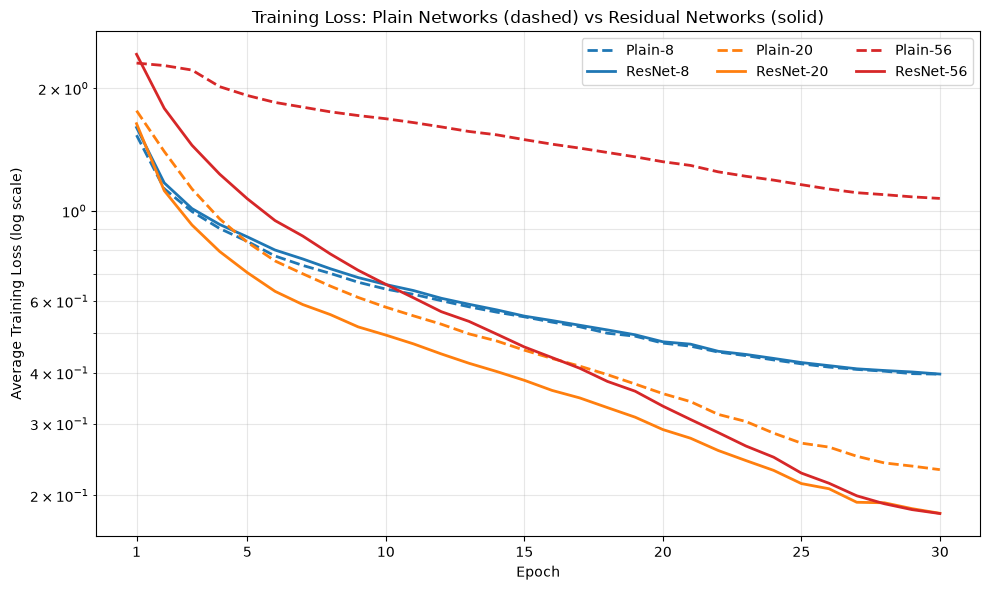

In [12]:
DEPTHS_3B = [8, 20, 56]

# One colour per depth; dashed = plain, solid = residual
DEPTH_COLORS_3B = {
    8: "tab:blue",
    20: "tab:orange",
    56: "tab:red"
}

EPOCH_TICKS_3B = [1] + list(range(5, EPOCHS_3B + 1, 5))


def plot_style_3b(name):
    family, depth = name.split("-")
    return {
        "color": DEPTH_COLORS_3B[int(depth)],
        "linestyle": "--" if family == "Plain" else "-",
        "linewidth": 2,
        "label": name
    }


def plot_all_networks_3b(key, ylabel, title, log_scale=False):

    plt.figure(figsize=(10, 6))

    for depth in DEPTHS_3B:
        for family in ["Plain", "ResNet"]:

            name = f"{family}-{depth}"
            values = histories_3b[name][key]

            plt.plot(
                range(1, len(values) + 1),
                values,
                **plot_style_3b(name)
            )

    if log_scale:
        plt.yscale("log")

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(EPOCH_TICKS_3B)

    plt.legend(ncol=3)
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_all_networks_3b(
    "train_loss",
    "Average Training Loss (log scale)",
    "Training Loss: Plain Networks (dashed) vs Residual Networks (solid)",
    log_scale=True
)

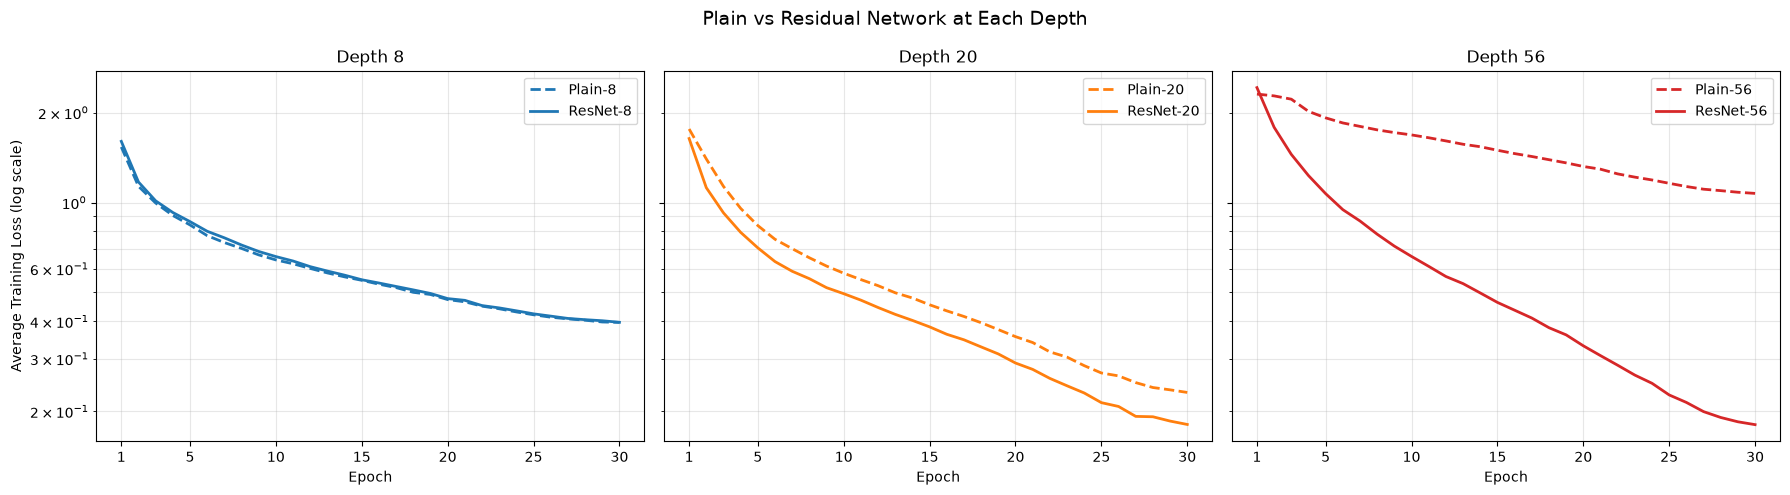

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, depth in zip(axes, DEPTHS_3B):

    for family in ["Plain", "ResNet"]:

        name = f"{family}-{depth}"
        losses = histories_3b[name]["train_loss"]

        ax.plot(
            range(1, len(losses) + 1),
            losses,
            **plot_style_3b(name)
        )

    ax.set_yscale("log")
    ax.set_title(f"Depth {depth}")
    ax.set_xlabel("Epoch")
    ax.set_xticks(EPOCH_TICKS_3B)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Average Training Loss (log scale)")

fig.suptitle("Plain vs Residual Network at Each Depth", fontsize=14)
plt.tight_layout()
plt.show()

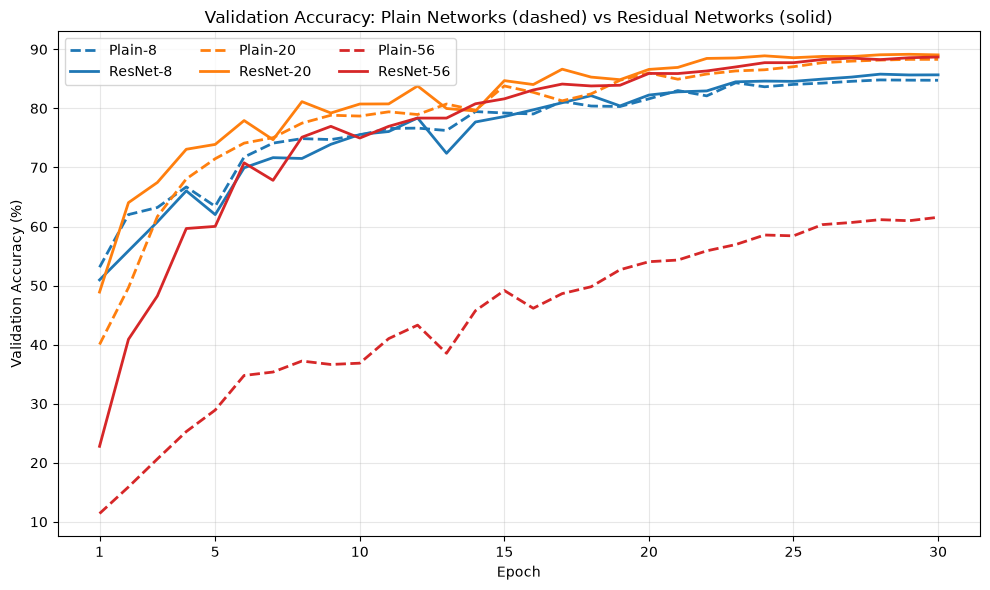

In [15]:
plot_all_networks_3b(
    "val_acc",
    "Validation Accuracy (%)",
    "Validation Accuracy: Plain Networks (dashed) vs Residual Networks (solid)"
)

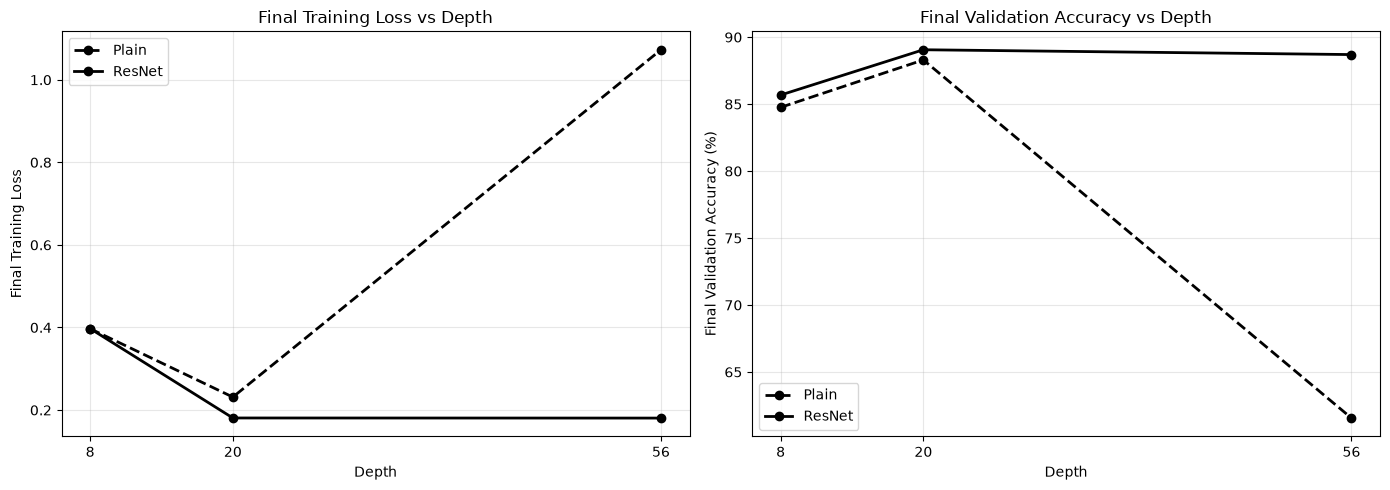

In [16]:
# How each family behaves as depth increases
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for family, linestyle in [("Plain", "--"), ("ResNet", "-")]:

    final_loss = [histories_3b[f"{family}-{d}"]["train_loss"][-1] for d in DEPTHS_3B]
    final_val = [histories_3b[f"{family}-{d}"]["val_acc"][-1] for d in DEPTHS_3B]

    axes[0].plot(DEPTHS_3B, final_loss, linestyle=linestyle, marker="o", linewidth=2, color="black", label=family)
    axes[1].plot(DEPTHS_3B, final_val, linestyle=linestyle, marker="o", linewidth=2, color="black", label=family)

axes[0].set_ylabel("Final Training Loss")
axes[0].set_title("Final Training Loss vs Depth")

axes[1].set_ylabel("Final Validation Accuracy (%)")
axes[1].set_title("Final Validation Accuracy vs Depth")

for ax in axes:
    ax.set_xlabel("Depth")
    ax.set_xticks(DEPTHS_3B)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [17]:
import pandas as pd

rows_3b = []

for depth in DEPTHS_3B:
    for family in ["Plain", "ResNet"]:

        h = histories_3b[f"{family}-{depth}"]

        rows_3b.append({
            "Network": f"{family}-{depth}",
            f"Train Loss @ Epoch {MID_EPOCH_3B}": h["train_loss"][MID_EPOCH_3B - 1],
            "Final Train Loss": h["train_loss"][-1],
            "Final Train Acc (%)": h["train_acc"][-1],
            "Final Val Acc (%)": h["val_acc"][-1],
            "Best Val Acc (%)": max(h["val_acc"])
        })

results_3b = pd.DataFrame(rows_3b)

print(
    results_3b.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}" if x < 10 else f"{x:.2f}"
    )
)

print()
print(
    f"{'Depth':<8}"
    f"{'Plain - ResNet Final Loss':<28}"
    f"{'ResNet - Plain Final Val Acc (pp)':<34}"
)
print("-" * 70)

for depth in DEPTHS_3B:

    plain = histories_3b[f"Plain-{depth}"]
    residual = histories_3b[f"ResNet-{depth}"]

    print(
        f"{depth:<8}"
        f"{plain['train_loss'][-1] - residual['train_loss'][-1]:<28.4f}"
        f"{residual['val_acc'][-1] - plain['val_acc'][-1]:<34.2f}"
    )

  Network  Train Loss @ Epoch 15  Final Train Loss  Final Train Acc (%)  Final Val Acc (%)  Best Val Acc (%)
  Plain-8                 0.5491            0.3970                86.34              84.76             84.82
 ResNet-8                 0.5514            0.3973                86.50              85.68             85.80
 Plain-20                 0.4548            0.2314                91.96              88.30             88.30
ResNet-20                 0.3835            0.1808                93.69              89.06             89.16
 Plain-56                 1.4959            1.0728                61.77              61.56             61.56
ResNet-56                 0.4631            0.1805                93.75              88.70             88.70

Depth   Plain - ResNet Final Loss   ResNet - Plain Final Val Acc (pp) 
----------------------------------------------------------------------
8       -0.0003                     0.92                              
20      0.0506         

### 7. Gradient Norms at Initialization

To check whether the difference between plain and residual networks is caused by vanishing gradients, the gradient norm of every convolutional layer is measured at initialization, before any training.

For Plain-56 and ResNet-56, the same mini-batch of 128 training images is passed through the network, the cross-entropy loss is backpropagated once, and the Frobenius norm

$$
G_l=\left\|\frac{\partial L}{\partial W_l}\right\|_F
$$

is recorded for each of the 55 convolutional layers. This is the same measurement as in Task 1(d), now applied to deep CNNs with batch normalization. No parameter updates are performed.

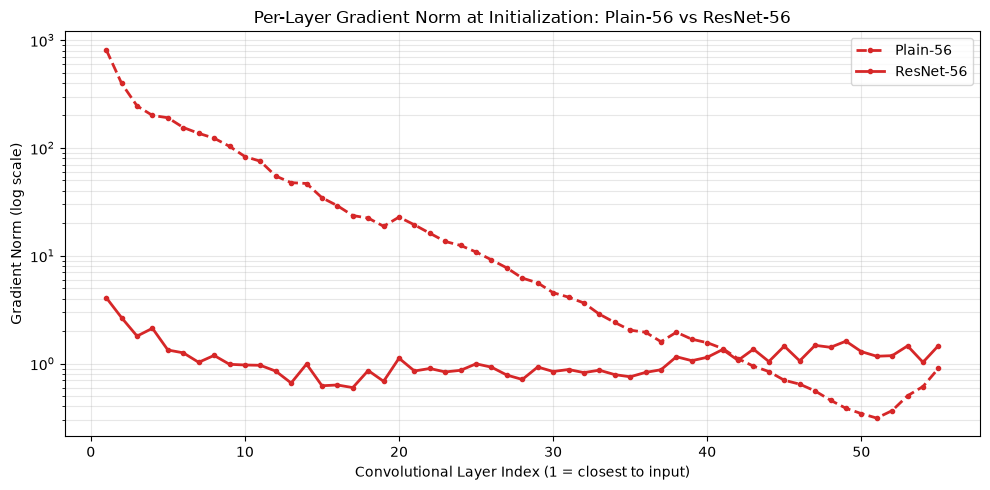

Network         First Conv     Last Conv    Last / First
--------------------------------------------------------
Plain-8            0.62187       0.42690            0.69
ResNet-8           0.95243       0.76141            0.80
Plain-20           1.98038       0.57532            0.29
ResNet-20          1.31983       0.86501            0.66
Plain-56         814.25647       0.90178            0.00
ResNet-56          4.08827       1.46678            0.36


In [18]:
def conv_gradient_norms_3b(depth, use_shortcuts, images, labels):

    torch.manual_seed(SEED_3B)

    model = CIFARNetwork(
        depth=depth,
        use_shortcuts=use_shortcuts
    ).to(DEVICE_3B)

    # Training mode so batch normalization uses batch statistics, as during training
    model.train()

    loss = F.cross_entropy(model(images), labels)
    loss.backward()

    norms = [
        m.weight.grad.norm().item()
        for m in model.modules()
        if isinstance(m, nn.Conv2d)
    ]

    del model
    return norms


# Same unaugmented mini-batch for every network
grad_images = X_train_3b[:BATCH_SIZE_3B]
grad_labels = y_train_3b[:BATCH_SIZE_3B]

grad_norms_3b = {
    f"{family}-{depth}": conv_gradient_norms_3b(
        depth, family == "ResNet", grad_images, grad_labels
    )
    for depth in DEPTHS_3B
    for family in ["Plain", "ResNet"]
}

plt.figure(figsize=(10, 5))

for name in ["Plain-56", "ResNet-56"]:
    norms = grad_norms_3b[name]
    plt.plot(
        range(1, len(norms) + 1),
        norms,
        marker="o",
        markersize=3,
        **plot_style_3b(name)
    )

plt.yscale("log")
plt.xlabel("Convolutional Layer Index (1 = closest to input)")
plt.ylabel("Gradient Norm (log scale)")
plt.title("Per-Layer Gradient Norm at Initialization: Plain-56 vs ResNet-56")

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'Network':<12}{'First Conv':>14}{'Last Conv':>14}{'Last / First':>16}")
print("-" * 56)

for name, norms in grad_norms_3b.items():
    print(
        f"{name:<12}"
        f"{norms[0]:>14.5f}"
        f"{norms[-1]:>14.5f}"
        f"{norms[-1] / norms[0]:>16.2f}"
    )

### 8. Experimental Results and Discussion

Six CIFAR-style CNNs were trained for 30 epochs under identical settings, initial weights, data order, and augmentation. The only difference between the two families is the shortcut.

#### 8.1 Training Loss Comparison

| Depth | Plain Loss @ Epoch 15 | ResNet Loss @ Epoch 15 | Plain Final Loss | ResNet Final Loss | Plain Final Val Acc (%) | ResNet Final Val Acc (%) |
|---|---:|---:|---:|---:|---:|---:|
| 8 | 0.5491 | 0.5514 | 0.3970 | 0.3973 | 84.76 | 85.68 |
| 20 | 0.4548 | 0.3835 | 0.2314 | 0.1808 | 88.30 | 89.06 |
| 56 | **1.4959** | 0.4631 | **1.0728** | 0.1805 | **61.56** | 88.70 |

#### 8.2 Degradation in Plain Networks

From Plain-8 to Plain-20, the final training loss decreases from 0.397 to 0.231, so the extra depth helps. However, **Plain-56 reaches a final loss of 1.073, which is higher than even Plain-8**, and its loss curve decreases slowly throughout training.

A 56-layer network could in principle copy Plain-20 and set its extra layers to the identity, so its training loss should be no higher. The higher loss therefore shows that the optimizer fails to find a good solution. This is the **degradation problem**.

It is not overfitting: Plain-56 has almost the same training and validation accuracy (61.77% vs 61.56%), so it is simply underfitted.

#### 8.3 Effect of Residual Connections

- **Depth 8:** the two curves are almost identical (final loss difference 0.0003). The network is too shallow for degradation to appear.
- **Depth 20:** ResNet-20 trains faster and ends with a lower loss (0.181 vs 0.231).
- **Depth 56:** the shortcuts remove the degradation completely. ResNet-56 reaches a final loss of 0.181 compared with 1.073 for Plain-56, and its validation accuracy is **27.1 percentage points higher** (88.70% vs 61.56%).

A residual block computes $y=\text{ReLU}(F(x)+x)$, so a block that should leave its input unchanged only needs $F(x)\approx 0$. This makes extra blocks easy to optimize, and the residual family no longer gets worse with depth.

ResNet-56 converges more slowly than ResNet-20 in early epochs and only matches its loss at the end. With the 30-epoch budget, the extra depth does not yet give a lower loss; the original paper, which trains about six times longer, shows deeper ResNets eventually reaching lower error.

#### 8.4 Is Degradation Caused by Vanishing Gradients?

The gradient-norm plot shows that the answer is **no**. In Plain-56, the gradient norm **grows** towards the input, from 0.90 at the last convolutional layer to 814 at the first, about 900 times larger. The early-layer gradients explode rather than vanish.

In ResNet-56, the gradient norm stays close to 1 across all 55 layers (1.47 at the last layer and 4.09 at the first).

This agrees with He et al. (2016): batch normalization prevents vanishing gradients, so degradation is an optimization problem. In Plain-56, the gradients of different layers differ by almost three orders of magnitude, so a single learning rate is far too large for the early layers and too small for the late layers, which makes training slow and inefficient. The identity shortcuts keep all layers on a similar scale.

This differs from Task 1(d), where a sigmoid MLP **without** batch normalization showed true vanishing gradients.

#### 8.5 Limitations

- 30 epochs with cosine annealing, compared with about 182 epochs and a step schedule in the original paper.
- Single random seed.
- The training loss is a running average over augmented mini-batches in training mode.

### 9. Conclusion

Plain networks improve from 8 to 20 layers but degrade sharply at 56 layers, where the training loss (1.073) is higher than that of the 8-layer network. Residual networks do not degrade: ResNet-56 trains as well as ResNet-20 and is 27 percentage points more accurate than Plain-56 on the validation set.

The gradient measurements show that the plain network's difficulty is not caused by vanishing gradients but by badly scaled (exploding) gradients in the early layers. Identity shortcuts keep the gradients balanced and make deep networks easy to optimize.

## Task 4: CNN design (optional)

**Question:**

Design the best CNN you can with at most 500k parameters and at most 20 training epochs. Tune on the validation split. Report an ablation of at least three design choices (e.g., shortcut, augmentation, weight decay, optimizer), and the test accuracy of your final model, evaluated once.

**Requirements:**

- The final CNN must have at most 500,000 parameters and be trained for at most 20 epochs.
- Tune all design choices using the validation split only.
- Report an ablation of at least three design choices (e.g., shortcut, augmentation, weight decay, optimizer).
- Report the test accuracy of the final model, evaluated only once.


### 1. Design

The final model is a **ResNet-32** ($n=5$) built with the `CIFARNetwork` class from Task 3(b). It is the deepest $6n+2$ network with 16/32/64 channels that stays under 500k parameters (ResNet-56 has 853k).

Design choices are based on the earlier tasks: residual shortcuts (Task 3(b)), flip + crop augmentation, the best regularizer in Task 3(a), and SGD with momentum and cosine annealing.

| Setting | Value |
|---|---|
| Model | ResNet-32 (about 464k parameters) |
| Epochs | 20 |
| Optimizer | SGD, momentum 0.9, initial LR 0.1 |
| LR schedule | Cosine annealing to 0.0001 |
| Weight decay | 0.0005 |
| Augmentation | Random crop (4-pixel reflection padding) + horizontal flip |
| Batch size | 128 |

**Note:** this task reuses `CIFARNetwork`, the GPU data tensors, `augment_batch_3b()` and `evaluate_3b()` from Task 3(b). Run the Task 3(b) cells up to and including the data-loading cell first (the Task 3(b) training does not need to be rerun).

In [19]:
from torchvision.datasets import CIFAR10

SEED_4 = 42
DEPTH_4 = 32
EPOCHS_4 = 20
BATCH_SIZE_4 = 128
LR_4 = 0.1
MIN_LR_4 = 1e-4
MAX_PARAMS_4 = 500_000

num_params_4 = sum(
    p.numel()
    for p in CIFARNetwork(DEPTH_4, use_shortcuts=True).parameters()
)

assert num_params_4 <= MAX_PARAMS_4

print(f"ResNet-{DEPTH_4} parameters: {num_params_4:,} (limit {MAX_PARAMS_4:,})")

ResNet-32 parameters: 464,154 (limit 500,000)


### 2. Ablation Design

Each ablation removes **one** design choice from the full model and keeps everything else fixed (leave-one-out). All four runs use the same seed and are compared on the **validation split only**.

| Configuration | Shortcuts | Augmentation | Weight Decay |
|---|---|---|---|
| Full model | Yes | Yes | 0.0005 |
| No shortcuts | No | Yes | 0.0005 |
| No augmentation | Yes | No | 0.0005 |
| No weight decay | Yes | Yes | 0 |

Removing the shortcuts does not change the parameter count, because the option-A shortcuts have no weights.

The ablation runs also serve as the tuning step: the configuration with the highest final validation accuracy is selected as the final model.

In [20]:
ABLATIONS_4 = {
    "Full model": {
        "shortcuts": True,
        "augment": True,
        "weight_decay": 5e-4
    },
    "No shortcuts": {
        "shortcuts": False,
        "augment": True,
        "weight_decay": 5e-4
    },
    "No augmentation": {
        "shortcuts": True,
        "augment": False,
        "weight_decay": 5e-4
    },
    "No weight decay": {
        "shortcuts": True,
        "augment": True,
        "weight_decay": 0.0
    }
}


def train_task4(name, config):

    # Reproducibility
    random.seed(SEED_4)
    np.random.seed(SEED_4)
    torch.manual_seed(SEED_4)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED_4)

    model = CIFARNetwork(
        depth=DEPTH_4,
        use_shortcuts=config["shortcuts"]
    ).to(DEVICE_3B)

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=LR_4,
        momentum=0.9,
        weight_decay=config["weight_decay"]
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS_4,
        eta_min=MIN_LR_4
    )

    criterion = nn.CrossEntropyLoss()

    # Reset randomness after initialization so the data order starts the same for every run
    torch.manual_seed(SEED_4)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    num_train = len(X_train_3b)

    progress = tqdm(range(1, EPOCHS_4 + 1), desc=name)

    for epoch in progress:

        model.train()

        total_loss = torch.zeros((), device=DEVICE_3B)
        total_correct = torch.zeros((), device=DEVICE_3B)

        order = torch.randperm(num_train, device=DEVICE_3B)

        for start in range(0, num_train, BATCH_SIZE_4):

            idx = order[start:start + BATCH_SIZE_4]

            images = X_train_3b[idx]
            labels = y_train_3b[idx]

            if config["augment"]:
                images = augment_batch_3b(images)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.detach() * images.size(0)
            total_correct += (outputs.argmax(dim=1) == labels).sum()

        train_loss = total_loss.item() / num_train
        train_acc = 100.0 * total_correct.item() / num_train

        if not np.isfinite(train_loss):
            raise RuntimeError(f"Non-finite loss in {name}")

        val_loss, val_acc = evaluate_3b(model, X_val_3b, y_val_3b)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        progress.set_postfix(
            loss=f"{train_loss:.4f}",
            val_acc=f"{val_acc:.2f}"
        )

        scheduler.step()

    print(
        f"{name:<16} | "
        f"Train Acc: {history['train_acc'][-1]:.2f}% | "
        f"Val Acc: {history['val_acc'][-1]:.2f}%"
    )

    # Keep the final weights on the CPU so the selected model can be tested later
    state_dict = {
        k: v.detach().cpu().clone()
        for k, v in model.state_dict().items()
    }

    del model, optimizer, scheduler

    if DEVICE_3B.type == "cuda":
        torch.cuda.empty_cache()

    return history, state_dict

### 3. Training

The four configurations are trained for 20 epochs each. Results and final weights are saved to `task4_results.pt` after every run, so an interrupted run can be resumed without retraining the finished configurations.

In [21]:
RESULTS_FILE_4 = "task4_results.pt"

# Set to True to ignore saved results and train all configurations again
RETRAIN_4 = False

if os.path.exists(RESULTS_FILE_4) and not RETRAIN_4:
    results_4 = torch.load(RESULTS_FILE_4)
    print("Loaded saved results for:", ", ".join(results_4))
else:
    results_4 = {}

for name, config in ABLATIONS_4.items():

    if name in results_4:
        print(f"Skipping {name} (already trained)")
        continue

    print(f"\nTraining {name}")

    history, state_dict = train_task4(name, config)

    results_4[name] = {
        "config": config,
        "history": history,
        "state_dict": state_dict
    }

    torch.save(results_4, RESULTS_FILE_4)

print("\nAll ablation runs completed.")


Training Full model


Full model:   0%|          | 0/20 [00:00<?, ?it/s]

Full model       | Train Acc: 93.00% | Val Acc: 89.98%

Training No shortcuts


No shortcuts:   0%|          | 0/20 [00:00<?, ?it/s]

No shortcuts     | Train Acc: 84.38% | Val Acc: 83.54%

Training No augmentation


No augmentation:   0%|          | 0/20 [00:00<?, ?it/s]

No augmentation  | Train Acc: 99.99% | Val Acc: 84.76%

Training No weight decay


No weight decay:   0%|          | 0/20 [00:00<?, ?it/s]

No weight decay  | Train Acc: 90.17% | Val Acc: 86.94%

All ablation runs completed.


### 4. Ablation Results

The change in validation accuracy is measured relative to the full model. A negative value means that removing the design choice made the model worse.

In [22]:
full_val_4 = results_4["Full model"]["history"]["val_acc"][-1]

rows_4 = []

for name in ABLATIONS_4:

    config = results_4[name]["config"]
    h = results_4[name]["history"]

    rows_4.append({
        "Configuration": name,
        "Shortcuts": "Yes" if config["shortcuts"] else "No",
        "Augmentation": "Yes" if config["augment"] else "No",
        "Weight Decay": f"{config['weight_decay']:g}",
        "Final Train Acc (%)": h["train_acc"][-1],
        "Final Val Acc (%)": h["val_acc"][-1],
        "Best Val Acc (%)": max(h["val_acc"]),
        "Change vs Full (pp)": h["val_acc"][-1] - full_val_4
    })

ablation_df_4 = pd.DataFrame(rows_4)

print(
    ablation_df_4.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

  Configuration Shortcuts Augmentation Weight Decay  Final Train Acc (%)  Final Val Acc (%)  Best Val Acc (%)  Change vs Full (pp)
     Full model       Yes          Yes       0.0005                93.00              89.98             89.98                 0.00
   No shortcuts        No          Yes       0.0005                84.38              83.54             83.54                -6.44
No augmentation       Yes           No       0.0005                99.99              84.76             84.90                -5.22
No weight decay       Yes          Yes            0                90.17              86.94             86.94                -3.04


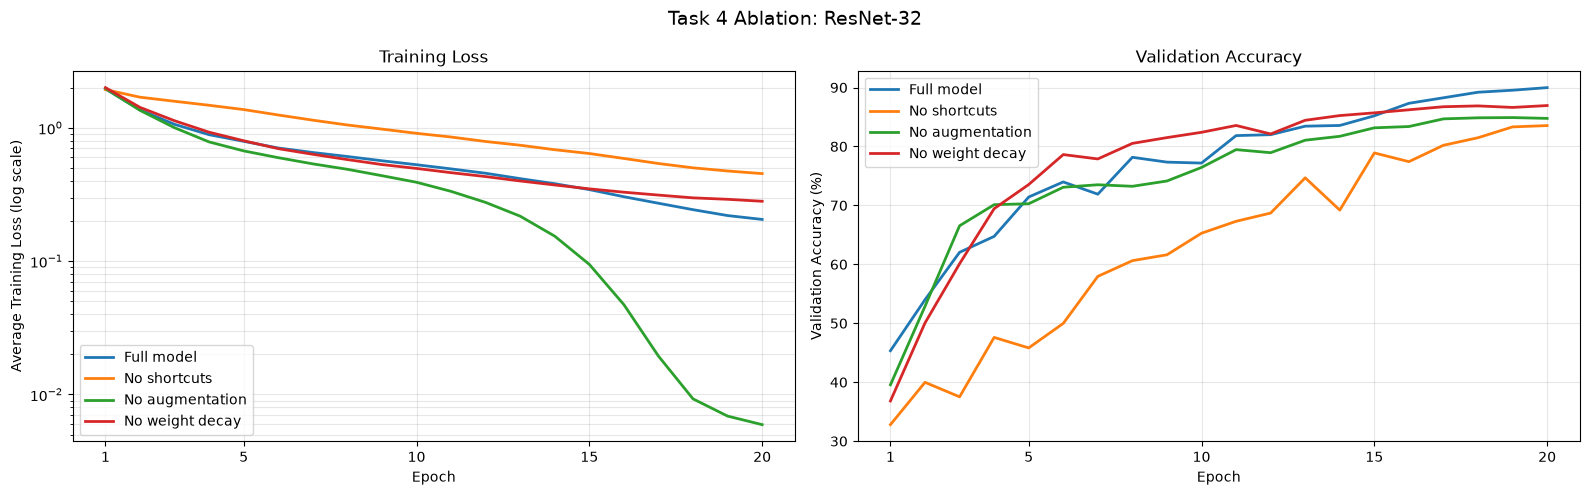

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
epochs_4 = range(1, EPOCHS_4 + 1)

for k, name in enumerate(ABLATIONS_4):

    h = results_4[name]["history"]
    style = {"color": plt.cm.tab10(k), "linewidth": 2, "label": name}

    axes[0].plot(epochs_4, h["train_loss"], **style)
    axes[1].plot(epochs_4, h["val_acc"], **style)

axes[0].set_yscale("log")
axes[0].set_ylabel("Average Training Loss (log scale)")
axes[0].set_title("Training Loss")

axes[1].set_ylabel("Validation Accuracy (%)")
axes[1].set_title("Validation Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_xticks([1] + list(range(5, EPOCHS_4 + 1, 5)))
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

fig.suptitle(f"Task 4 Ablation: ResNet-{DEPTH_4}", fontsize=14)
plt.tight_layout()
plt.show()

### 5. Final Model and Test Accuracy

The final model is the configuration with the highest final validation accuracy. The test set is loaded with the same training-set normalization as in Task 1, and it is evaluated **only once**, in the cell below.

In [24]:
# Selection uses validation accuracy only; the test set plays no part in it
final_name_4 = max(
    ABLATIONS_4,
    key=lambda n: results_4[n]["history"]["val_acc"][-1]
)

print("Selected configuration:", final_name_4)
print(f"Validation accuracy: {results_4[final_name_4]['history']['val_acc'][-1]:.2f}%")

# Test set with the same ToTensor + Normalize (training statistics) transform as Task 1
test_set_4 = CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=train_dataset.dataset.transform
)

X_test_4, y_test_4 = to_device_tensors(test_set_4, DEVICE_3B)
assert X_test_4.shape == (10000, 3, 32, 32)

final_model_4 = CIFARNetwork(
    depth=DEPTH_4,
    use_shortcuts=results_4[final_name_4]["config"]["shortcuts"]
).to(DEVICE_3B)

final_model_4.load_state_dict(results_4[final_name_4]["state_dict"])

# Single evaluation on the test set
test_loss_4, test_acc_4 = evaluate_3b(final_model_4, X_test_4, y_test_4)

print(f"Parameters: {sum(p.numel() for p in final_model_4.parameters()):,}")
print(f"Test accuracy: {test_acc_4:.2f}%")

Selected configuration: Full model
Validation accuracy: 89.98%
Parameters: 464,154
Test accuracy: 89.57%


### 6. Discussion

| Configuration | Final Train Acc (%) | Final Val Acc (%) | Change vs Full (pp) |
|---|---:|---:|---:|
| **Full model** | 93.00 | **89.98** | — |
| No shortcuts | 84.38 | 83.54 | −6.44 |
| No augmentation | 99.99 | 84.76 | −5.22 |
| No weight decay | 90.17 | 86.94 | −3.04 |

**Final model:** ResNet-32 with 464,154 parameters, trained for 20 epochs. It was selected on validation accuracy (89.98%) and achieved a **test accuracy of 89.57%**, evaluated once.

Removing any of the three design choices reduced validation accuracy, so all three contribute to the final model.

**Shortcuts (−6.44 pp):** the largest effect. Without shortcuts, the training loss decreases much more slowly and the training accuracy is only 84.38%, so the plain network underfits. This is the same degradation seen in Task 3(b), now at 32 layers: shortcuts make the deep network easy to optimize.

**Augmentation (−5.22 pp):** without flip + crop, the network memorizes the training set (99.99% training accuracy, training loss about 0.006) while validation accuracy stops near 85%, a gap of 15 points. With augmentation the gap is only 3 points. As in Task 3(a), augmentation was the most effective regularizer, and it remains important even with 45k training images.

**Weight decay (−3.04 pp):** in Task 3(a), weight decay had almost no effect, but here it gives a clear improvement. Interestingly, the run without weight decay was ahead for the first 15 epochs, and the full model only overtook it as the learning rate decayed. It also ends with a higher training loss (0.28 vs 0.21) than the full model. This suggests that, with batch normalization, weight decay mainly acts by keeping the weights small, which keeps the effective learning rate high and lets optimization continue to make progress late in training, rather than acting only as a classic L2 regularizer.

**Test accuracy:** the test accuracy (89.57%) is only 0.41 points below the validation accuracy, which indicates that the model selection did not overfit the validation split.

**Limitations:** a single seed was used; with only four runs, the tuning was limited to these design choices; longer training or a wider network would likely improve accuracy further within the parameter limit.

## Acknowledgement of AI Tool Usage

Claude used through Claude Code in VS Code, was used as an assistant during this assignment for help with writing and debugging code, improving plots, and drafting parts of the explanations and discussions. All experiments were run by me, and all code and results were reviewed and are understood by me.